# 10. Reticles, one sensor plane at a time

This notebook looks at one sensor plane of one simulated shower in two ways: as the simulation
knows it (which particle left which charge on which pixel) and as the detector sees it (a map of
pixels that are on or off). It then cuts the plane into reticles, defines what a reticle should
count, and shows what happens to the picture as the density of particles rises.

Nothing here estimates a count from the hit map; that is notebook 11. Nothing here sums over the
layers of a shower; that is notebook 12.

**Where this notebook sits in the chain**

```
Geant4 shower: the energy deposited in every step in the silicon
  -> PIXELAV: the charge each particle leaves on each pixel       charges_b0.npz  (20 showers)
  -> reticles.py: blocks of 21 x 13 pixels and their truth        ret_K1.npz ... ret_K8.npz  (200 showers)
  -> this notebook: one plane, its reticles, rising density
  -> notebook 11: the count of each reticle estimated from its hit map
  -> notebook 12: the counts summed over a shower
```

**What you need beforehand**

- An electromagnetic shower: a high-energy photon converts into an electron and a positron in
  the tungsten, these radiate new photons, and so on, until the energy is shared among many
  low-energy particles. Notebook 01 shows this for the whole calorimeter.
- A charged particle that crosses silicon frees electron-hole pairs, on average one pair per
  3.68 eV of deposited energy. An electric field drifts the charge to the pixels. The charge of a
  pixel is counted in electrons (e).
- A minimum ionising particle (MIP) is a charged particle fast enough that its energy loss per
  unit length sits near the minimum. Electrons and positrons above a few MeV behave roughly like
  MIPs, and they make up nearly all the charged particles here.
- The study behind this notebook is `docs/reticle_mip_counting.md`. Its sections 1 to 4 cover the
  same ground in a shorter form.

**The detector in one paragraph.** The DECAL (digital electromagnetic calorimeter) studied here
is a barrel of 12 flat modules around the beam line. Each module has 30 layers of silicon sensors
behind tungsten plates. Each sensor is cut into pixels of 50 um x 25 um and is 100 um thick. A
pixel reports only whether its charge passed a threshold: on or off. On a sensor, v runs along
the barrel and u across it, so a pixel is 50 um long along v and 25 um along u. The simulated
showers are of 50 GeV photons, all along one line, the shower axis, which crosses one module at
right angles: the axis module.

**Why count per reticle.** Pixels this small make far more hits than the detector can send out.
The energy measurement does not need the hits; it needs the number of charged particles that
crossed each layer. The idea studied here is logic at the edge of each sensor, the edge logic: it
reads a fixed block of pixels, a reticle, and sends out one number, the count of particles that
crossed it (section 4 makes this precise: the count of crossings). In this study the edge logic
sees only the on/off bits of its own reticle: no charge, no neighbouring reticles, no position of
the shower axis. This notebook shows what such a count should be; notebook 11 asks how well it can
be made.

## 1. Configuration and loading

Two kinds of input files are used, both made by the scripts in `analysis/pixelav/`:

- `charges_b0.npz`: the charge of every particle on every pixel, for 20 showers of 50 GeV photons
  (one batch of the sample; written by `charge_maps.py`).
- `ret_K1.npz` and `ret_K8.npz`: the same kind of showers, 200 of them, already cut into reticles
  (written by `reticles.py`). `K8` stacks 8 showers on top of each other to raise the density.

The data directory is `models/reticle_study/` in the repository, or the directory named by the
environment variable `CALOMAPS_RETICLE_STUDY`.

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap
from matplotlib.patches import Rectangle
from matplotlib.collections import LineCollection
from scipy.stats import norm

T_START = time.time()
REPO = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA = os.environ.get('CALOMAPS_RETICLE_STUDY', os.path.join(REPO, 'models', 'reticle_study'))
sys.path.insert(0, os.path.join(REPO, 'analysis', 'pixelav'))
import reticles                  # tiling and truth objects (analysis/pixelav/reticles.py)
import mip_counting as mc        # readout model and reticle truths (analysis/pixelav/mip_counting.py)


def need(name):
    # the path of an input file, or a clear error naming it
    path = os.path.join(DATA, name)
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"{path} is missing. The charges file is the output of analysis/pixelav/charge_maps.py for "
            "batch 0 of the sample, and the ret_K*.npz files are made by analysis/pixelav/reticles.py; "
            "see docs/reticle_mip_counting.md section 9 for the commands. Put them in "
            "models/reticle_study/ or point CALOMAPS_RETICLE_STUDY at their directory.")
    return path


EVENT = 2              # the display shower: it starts early, in the first layers
EARLY_LAYER = 2        # an early layer for section 3
THRESHOLD = mc.THRESHOLD   # electrons: a pixel above this is "hit" (on)
NOISE = mc.NOISE           # electrons: Gaussian noise per pixel (sigma)
SEED = 1
SIZE_X, SIZE_Y = reticles.SIZE_X, reticles.SIZE_Y   # a reticle: 21 pixels along v, 13 along u
OFFSET_X, OFFSET_Y = 10, 6     # grid offsets of the reticle files (pixels along v and u)
SHOW_Q = NOISE                 # electrons: the least charge drawn in the "truth" pictures
print(f"repository: {REPO}\ndata: {DATA}")
print(f"threshold {THRESHOLD:g} e, noise {NOISE:g} e, reticle {SIZE_X} x {SIZE_Y} pixels, "
      f"grid offsets ({OFFSET_X}, {OFFSET_Y})")

repository: /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms
data: /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms/models/reticle_study
threshold 1000 e, noise 100 e, reticle 21 x 13 pixels, grid offsets (10, 6)


In [2]:
with np.load(need('charges_b0.npz'), allow_pickle=False) as d:
    C = {k: d[k] for k in d.files}

PITCH_V, PITCH_U = float(C['pitch_x_um']), float(C['pitch_y_um'])   # um: v is along the barrel, u across
THICK = float(C['thick_um'])
EV_PER_PAIR = float(C['ev_per_pair'])
N_LAYERS = len(C['geo_si_centers_mm'])
N_FACES = reticles.sc.N_FACES
AXIS_MODULE = reticles.axis_module()

pix_g = C['pix_group_id'].astype(np.int64)
pix_iv = C['pix_iv'].astype(np.int64)
pix_iu = C['pix_iu'].astype(np.int64)
pix_q = C['pix_q']                                   # float32, electrons
grp_evt, grp_mod, grp_lay = (C[k].astype(np.int64) for k in ('group_evt_id', 'group_module', 'group_layer'))
print(f"{int(C['num_events'])} showers of {float(C['sim_gun_energy_GeV']):g} GeV {C['sim_gun_particle']}, "
      f"{len(grp_evt):,} particle-plane groups, {len(pix_q):,} (group, pixel) rows")
print(f"pixels {PITCH_V:g} x {PITCH_U:g} um (v x u), silicon {THICK:g} um, {EV_PER_PAIR} eV per pair, "
      f"{N_FACES} modules, {N_LAYERS} layers; the shower axis enters module {AXIS_MODULE}")

20 showers of 50 GeV gamma, 62,579 particle-plane groups, 494,286 (group, pixel) rows
pixels 50 x 25 um (v x u), silicon 100 um, 3.68 eV per pair, 12 modules, 30 layers; the shower axis enters module 7


The arrays of the charges file used here:

| array | one entry per | meaning |
|---|---|---|
| `pix_group_id`, `pix_iv`, `pix_iu`, `pix_q` | (group, pixel) | the charge in electrons that one group left on pixel (`iv`, `iu`) |
| `group_evt_id`, `group_module`, `group_layer` | group | the sensor plane of the group: shower, module, layer |
| `group_q`, `group_edep_keV` | group | its total charge (e) and the energy it deposited in the silicon (keV) |
| `group_root_pdg`, `group_root_p_MeV` | group | the particle type (11 electron, -11 positron) and its momentum when it entered the plane |
| `group_path_um` | group | the summed length of its steps in the silicon |
| `group_u_min_um` ... `group_v_max_um` | group | the range of its steps in u and v: how far it reached sideways |

A **group** is one charged particle in one sensor plane, together with the secondary electrons
(delta rays) it knocked out in the same slab of silicon. Below, "particle" means a group.
A **sensor plane** is one layer of one module in one shower.

Pixel coordinates: `iv` counts 50 um pixels along v and `iu` counts 25 um pixels along u; pixel
`iv` covers v from `iv x 50` to `(iv + 1) x 50` um. The shower axis crosses the axis module at the
pixel corner (iv, iu) = (0, 0). In every picture below, v runs to the right and u runs up.

In [3]:
assert np.array_equal(C['group_id'], np.arange(len(C['group_id']))), "group_id is not the row index"
print("check: group_id equals the row index of the group arrays, so group g is row g")

# the plane of every pixel row
row_evt, row_mod, row_lay = grp_evt[pix_g], grp_mod[pix_g], grp_lay[pix_g]
on_axis_module = np.mean(grp_mod == AXIS_MODULE)
print(f"{100 * on_axis_module:.2f}% of the groups lie on the axis module {AXIS_MODULE}; the rest are "
      "a few stray particles on other modules")
print(f"pixel rows with negative charge: {np.count_nonzero(pix_q < 0)} (smallest {pix_q.min():.2f} e), "
      f"below {SHOW_Q:g} e: {100 * np.mean(pix_q < SHOW_Q):.1f}% of the rows")

check: group_id equals the row index of the group arrays, so group g is row g
99.95% of the groups lie on the axis module 7; the rest are a few stray particles on other modules
pixel rows with negative charge: 23 (smallest -0.10 e), below 100 e: 14.5% of the rows


## 2. One plane of one shower

We take shower 2 (it starts early, so its maximum lies well inside the 30 layers) and the layer
where it leaves the most charge on the axis module: a layer near the shower maximum.

In [4]:
sel_evt = (grp_evt == EVENT) & (grp_mod == AXIS_MODULE)
q_layer = np.bincount(grp_lay[sel_evt], C['group_q'][sel_evt], N_LAYERS)
n_layer = np.bincount(grp_lay[sel_evt], minlength=N_LAYERS)
LAYER = int(np.argmax(q_layer))
print("layer:          " + " ".join(f"{l:5d}" for l in range(16)))
print("charge [1e6 e]: " + " ".join(f"{q / 1e6:5.2f}" for q in q_layer[:16]))
print("particles:      " + " ".join(f"{n:5d}" for n in n_layer[:16]))
print(f"\nshower {EVENT}: the most charge is in layer {LAYER}; it is used below")

plane_rows = np.flatnonzero((row_evt == EVENT) & (row_mod == AXIS_MODULE) & (row_lay == LAYER))
plane_groups = np.flatnonzero(sel_evt & (grp_lay == LAYER))
print(f"plane (shower {EVENT}, module {AXIS_MODULE}, layer {LAYER}): {len(plane_groups)} particles, "
      f"{len(plane_rows):,} (particle, pixel) rows")

layer:              0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15
charge [1e6 e]:  0.27  0.51  0.75  1.69  1.89  2.95  3.34  4.55  4.74  4.82  5.79  5.09  4.33  4.59  3.58  3.34
particles:         16    25    55    94   125   173   212   268   264   269   259   232   212   187   187   158

shower 2: the most charge is in layer 10; it is used below
plane (shower 2, module 7, layer 10): 259 particles, 2,286 (particle, pixel) rows


**The plane.** Pixels are far too small to see at this scale, so the charge is summed in cells of
0.25 mm x 0.25 mm, over the central 32 mm x 32 mm of the plane (a few stray particles lie farther
out; their share is printed). Look for a dense core around the axis (inside the red box) and a
wide, thin halo of particles that scattered far from it. The colour scale is logarithmic.

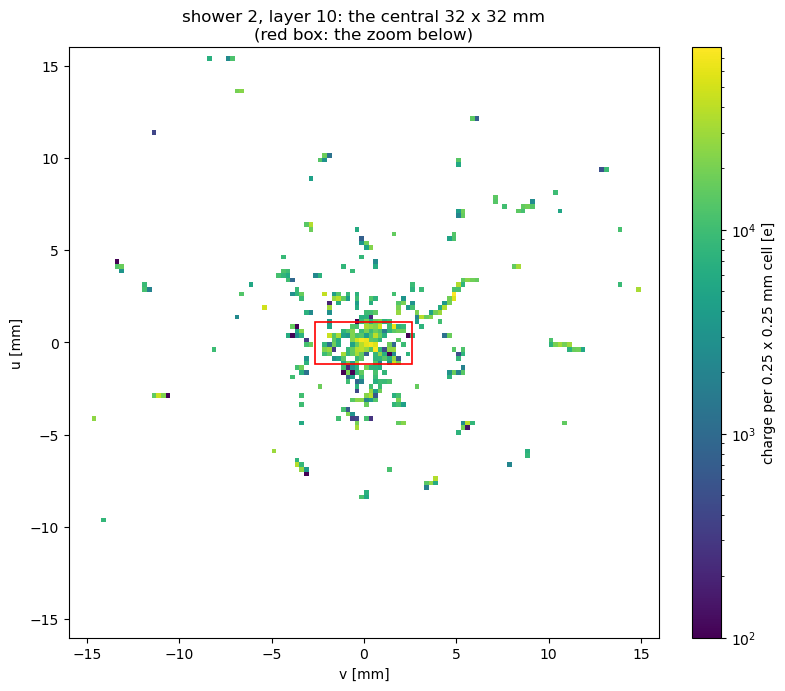

share of the plane's charge within 1 mm of the axis: 0.19
share of the plane's charge within 5 mm of the axis: 0.65
outside the picture: 0.045 of the charge; the farthest pixel with charge is 139 mm from the axis


In [5]:
v_mm = (pix_iv[plane_rows] + 0.5) * PITCH_V * 1e-3
u_mm = (pix_iu[plane_rows] + 0.5) * PITCH_U * 1e-3
q_pl = pix_q[plane_rows].astype(np.float64)
CELL, HALF = 0.25, 16.0
ev = eu = np.arange(-HALF, HALF + CELL / 2, CELL)
H, _, _ = np.histogram2d(v_mm, u_mm, bins=[ev, eu], weights=q_pl)

# the zoom used in sections 2, 5 and 6: 5 x 7 reticles centred on the reticle that holds the axis
RV_AXIS = int(np.floor_divide(0 - OFFSET_X, SIZE_X))
RU_AXIS = int(np.floor_divide(0 - OFFSET_Y, SIZE_Y))
Z_NRV, Z_NRU = 5, 7
Z_IV0 = OFFSET_X + (RV_AXIS - Z_NRV // 2) * SIZE_X
Z_IU0 = OFFSET_Y + (RU_AXIS - Z_NRU // 2) * SIZE_Y
Z_NV, Z_NU = Z_NRV * SIZE_X, Z_NRU * SIZE_Y

fig, ax = plt.subplots(figsize=(8, 6.8), constrained_layout=True)
m = ax.pcolormesh(ev, eu, np.where(H > 0, H, np.nan).T, norm=LogNorm(vmin=1e2, vmax=H.max()), cmap='viridis')
fig.colorbar(m, ax=ax, label='charge per 0.25 x 0.25 mm cell [e]')
ax.add_patch(Rectangle((Z_IV0 * PITCH_V * 1e-3, Z_IU0 * PITCH_U * 1e-3), Z_NV * PITCH_V * 1e-3,
                       Z_NU * PITCH_U * 1e-3, fill=False, ec='red', lw=1.2))
ax.set_aspect('equal')
ax.set_xlabel('v [mm]')
ax.set_ylabel('u [mm]')
ax.set_title(f'shower {EVENT}, layer {LAYER}: the central 32 x 32 mm\n(red box: the zoom below)')
plt.show()

r_mm = np.hypot(v_mm, u_mm)
for R in (1.0, 5.0):
    print(f"share of the plane's charge within {R:g} mm of the axis: {np.sum(q_pl[r_mm < R]) / q_pl.sum():.2f}")
outside = (np.abs(v_mm) >= HALF) | (np.abs(u_mm) >= HALF)
print(f"outside the picture: {np.sum(q_pl[outside]) / q_pl.sum():.3f} of the charge; the farthest pixel with "
      f"charge is {r_mm.max():.0f} mm from the axis")

The charge is densest on the axis, but near the shower maximum most of it lies more than a
millimetre away (the printed shares): the shower is a narrow core inside a halo several millimetres
wide, with stray particles centimetres out.

**The core, pixel by pixel.** The red box above is 5 x 7 reticles (a reticle is defined in
section 6), about 5.3 mm x 2.3 mm. Each rectangle below is one pixel, drawn with its true
shape: twice as long along v as along u. Look for small clumps of a few pixels (single
particles) and a few long or large patches.

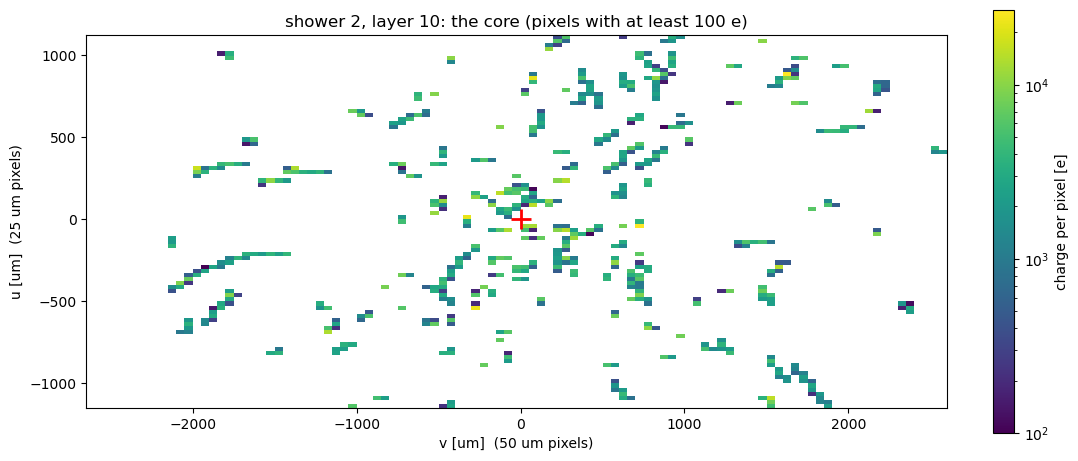

pixels with charge >= 100 e in the zoom: 569 of 9555; above 1000 e: 437; largest pixel 27,005 e


In [6]:
def pixel_image(iv, iu, q, iv0, iu0, nv, nu):
    # the summed charge [nu, nv] of pixel rows in the window of nv x nu pixels starting at (iv0, iu0)
    m = (iv >= iv0) & (iv < iv0 + nv) & (iu >= iu0) & (iu < iu0 + nu)
    flat = np.bincount((iu[m] - iu0) * nv + (iv[m] - iv0), q[m].astype(np.float64), nu * nv)
    return flat.reshape(nu, nv)


def extent_um(iv0, iu0, nv, nu):
    # imshow extent of a pixel window in um, so that pixels keep their 50 x 25 um shape
    return (iv0 * PITCH_V, (iv0 + nv) * PITCH_V, iu0 * PITCH_U, (iu0 + nu) * PITCH_U)


zoom_q = pixel_image(pix_iv[plane_rows], pix_iu[plane_rows], pix_q[plane_rows], Z_IV0, Z_IU0, Z_NV, Z_NU)
fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(np.where(zoom_q >= SHOW_Q, zoom_q, np.nan), origin='lower', interpolation='nearest',
               extent=extent_um(Z_IV0, Z_IU0, Z_NV, Z_NU), norm=LogNorm(vmin=SHOW_Q, vmax=zoom_q.max()),
               cmap='viridis')
fig.colorbar(im, ax=ax, label='charge per pixel [e]', fraction=0.025)
ax.plot(0, 0, '+', color='red', ms=14, mew=2)
ax.set_xlabel('v [um]  (50 um pixels)')
ax.set_ylabel('u [um]  (25 um pixels)')
ax.set_title(f'shower {EVENT}, layer {LAYER}: the core (pixels with at least {SHOW_Q:g} e)')
plt.show()
print(f"pixels with charge >= {SHOW_Q:g} e in the zoom: {np.count_nonzero(zoom_q >= SHOW_Q)} of {zoom_q.size}; "
      f"above {THRESHOLD:g} e: {np.count_nonzero(zoom_q > THRESHOLD)}; largest pixel {zoom_q.max():,.0f} e")

Even at the shower maximum most pixels of the core are empty (the printed count). Each clump is one
particle or a few touching ones; section 3 tells them apart.

**Two checks on the charge.**

1. The pixel charges of the plane must add up to the charges of its particles (`group_q`, which
   the charge collector summed in double precision before storing the pixels in single precision).
2. The charge must equal the deposited energy divided by 3.68 eV per pair. PIXELAV makes a whole
   number of pairs from each piece of track (at most 5 um long): the pair count of a piece is
   rounded down or up. So the charge may differ from energy / 3.68 eV by at most one pair per
   piece, and a group has at most `n_steps + path / 5 um` pieces. That is the tolerance.

In [7]:
q_pix_sum = float(pix_q[plane_rows].astype(np.float64).sum())
q_grp_sum = float(C['group_q'][plane_groups].sum())
rel = abs(q_pix_sum - q_grp_sum) / q_grp_sum
assert rel < 1e-6, f"pixel charges {q_pix_sum:.1f} e vs group charges {q_grp_sum:.1f} e"
print(f"check 1: pixel charges {q_pix_sum:,.1f} e, group charges {q_grp_sum:,.1f} e, "
      f"relative difference {rel:.1e}")

pairs = float(C['group_edep_keV'][plane_groups].sum()) * 1e3 / EV_PER_PAIR
bound = float(np.sum(C['group_n_steps'][plane_groups] + C['group_path_um'][plane_groups] / float(C['piece_um'])))
assert int(C['total_n_out']) == 0, "some pairs were made outside a job window and not transported"
assert abs(q_grp_sum - pairs) <= bound, f"charge {q_grp_sum:.0f} e vs energy / {EV_PER_PAIR} eV = {pairs:.0f}"
print(f"check 2: charge / (deposited energy / {EV_PER_PAIR} eV) = {q_grp_sum / pairs:.6f} on this plane; "
      f"difference {q_grp_sum - pairs:+,.0f} e, allowed by the rounding of pairs: {bound:,.0f} e")

# the same on every plane of the 20 showers
pk = (grp_evt * N_FACES + grp_mod) * N_LAYERS + grp_lay
_, pinv = np.unique(pk, return_inverse=True)
pinv = pinv.ravel()
q_p = np.bincount(pinv, C['group_q'])
e_p = np.bincount(pinv, C['group_edep_keV']) * 1e3 / EV_PER_PAIR
b_p = np.bincount(pinv, C['group_n_steps'] + C['group_path_um'] / float(C['piece_um']))
assert np.all(np.abs(q_p - e_p) <= b_p)
big = e_p > 1e5
print(f"all {len(q_p)} planes holding charge in the {int(C['num_events'])} showers pass; ratio on the planes above 1e5 e: "
      f"{(q_p / e_p)[big].min():.5f} to {(q_p / e_p)[big].max():.5f}; whole sample {q_p.sum() / e_p.sum():.7f}")

check 1: pixel charges 5,788,295.0 e, group charges 5,788,295.0 e, relative difference 0.0e+00
check 2: charge / (deposited energy / 3.68 eV) = 1.000004 on this plane; difference +24 e, allowed by the rounding of pairs: 27,453 e
all 604 planes holding charge in the 20 showers pass; ratio on the planes above 1e5 e: 0.99984 to 1.00008; whole sample 0.9999997


Both checks hold. The charge equals the deposited energy divided by 3.68 eV to a small fraction
of a percent on every plane with appreciable charge, so in what follows charge and deposited energy
are interchangeable. Only planes with a handful of pairs deviate more, as the rounding allows.

## 3. Who made which pixel

The simulation knows which particle left which charge. Here we draw that next to what the
detector sees, for three windows of 3 x 3 reticles (3.15 mm x 0.975 mm each):

- an early layer, on the shower axis;
- the layer of section 2, on the axis;
- the same layer, about 2 mm to the side of the axis (six reticles along u).

Left, (a): every pixel holding at least 100 e (the noise level of section 5), coloured by the
particle that left most of its charge there. Colours repeat, so two far-apart particles may share
one. Right, (b): the pixels whose summed charge passes the threshold of 1000 e, in black (noise is
added only in section 5). Red lines are reticle edges. Look for particles whose pixels touch, so
that (b) shows one patch where (a) shows two or more colours.

In [8]:
PALETTE = np.vstack([plt.get_cmap(n).colors for n in ('tab20', 'tab20b', 'tab20c')])[:, :3]


def window(evt, layer, rv_c, ru_c, nrv=3, nru=3):
    # pixel rows of the nrv x nru reticles centred on reticle (rv_c, ru_c), and the window's pixels
    iv0 = OFFSET_X + (rv_c - nrv // 2) * SIZE_X
    iu0 = OFFSET_Y + (ru_c - nru // 2) * SIZE_Y
    nv, nu = nrv * SIZE_X, nru * SIZE_Y
    rows = np.flatnonzero((row_evt == evt) & (row_mod == AXIS_MODULE) & (row_lay == layer)
                          & (pix_iv >= iv0) & (pix_iv < iv0 + nv) & (pix_iu >= iu0) & (pix_iu < iu0 + nu))
    return rows, iv0, iu0, nv, nu


def owner_image(rows, iv0, iu0, nv, nu):
    # per pixel of the window: the group that left the most charge there (-1 for none)
    pix = (pix_iu[rows] - iu0) * nv + (pix_iv[rows] - iv0)
    o = np.lexsort((-pix_q[rows], pix))
    first = o[np.r_[True, np.diff(pix[o]) != 0]]
    own = np.full(nu * nv, -1, np.int64)
    own[pix[first]] = pix_g[rows][first]
    return own.reshape(nu, nv)


def draw_grid(ax, iv0, iu0, nv, nu):
    for k in range(0, nv + 1, SIZE_X):
        ax.axvline((iv0 + k) * PITCH_V, color='red', lw=0.8)
    for k in range(0, nu + 1, SIZE_Y):
        ax.axhline((iu0 + k) * PITCH_U, color='red', lw=0.8)


def draw_truth_and_hits(ax_t, ax_h, rows, iv0, iu0, nv, nu, label):
    # (a) pixels coloured by the particle that left most of their charge, (b) the pixels above threshold
    q = pixel_image(pix_iv[rows], pix_iu[rows], pix_q[rows], iv0, iu0, nv, nu)
    own = owner_image(rows, iv0, iu0, nv, nu)
    rgb = np.ones((nu, nv, 3))
    show = (q >= SHOW_Q) & (own >= 0)
    rgb[show] = PALETTE[(own[show] * 7) % len(PALETTE)]
    ext = extent_um(iv0, iu0, nv, nu)
    ax_t.imshow(rgb, origin='lower', interpolation='nearest', extent=ext)
    hit = q > THRESHOLD
    ax_h.imshow(hit, origin='lower', interpolation='nearest', extent=ext, cmap=ListedColormap(['white', '0.15']),
                vmin=0, vmax=1)
    q_grp = np.bincount(pix_g[rows], pix_q[rows].astype(np.float64))
    above = np.flatnonzero(q_grp > THRESHOLD)
    for ax in (ax_t, ax_h):
        draw_grid(ax, iv0, iu0, nv, nu)
        ax.set_xlabel('v [um]')
        ax.set_ylabel('u [um]')
    ax_t.set_title(f'(a) {label}: {len(above)} particles above {THRESHOLD:g} e', fontsize=10)
    ax_h.set_title(f'(b) what the detector sees: {int(hit.sum())} hit pixels', fontsize=10)
    return len(above), int(hit.sum()), float(np.median(C['group_root_p_MeV'][above]))

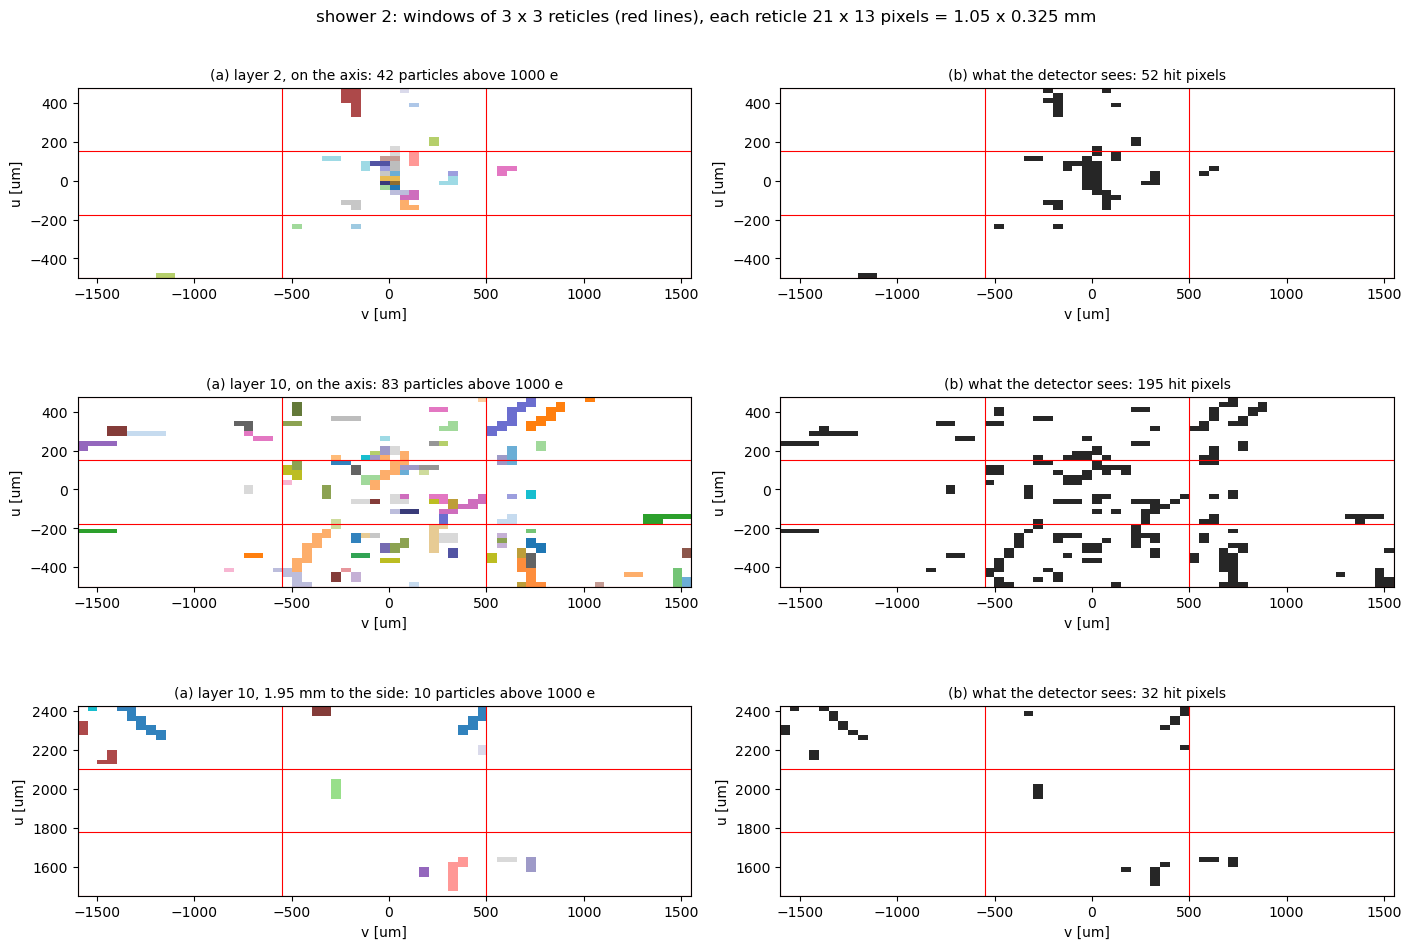

layer 2, on the axis            :   42 particles above 1000 e,   52 hit pixels, 1.2 hit pixels per particle, median momentum 105.9 MeV/c
layer 10, on the axis           :   83 particles above 1000 e,  195 hit pixels, 2.3 hit pixels per particle, median momentum 25.5 MeV/c
layer 10, 1.95 mm to the side   :   10 particles above 1000 e,   32 hit pixels, 3.2 hit pixels per particle, median momentum 10.9 MeV/c


In [9]:
SIDE_RU = 6     # reticles along u: 6 x 325 um = 1.95 mm
windows = [(EARLY_LAYER, RU_AXIS, f'layer {EARLY_LAYER}, on the axis'),
           (LAYER, RU_AXIS, f'layer {LAYER}, on the axis'),
           (LAYER, RU_AXIS + SIDE_RU, f'layer {LAYER}, {SIDE_RU * SIZE_Y * PITCH_U / 1e3:.2f} mm to the side')]
fig, axs = plt.subplots(3, 2, figsize=(14, 9.5), constrained_layout=True)
counts = []
for (layer, ru_c, label), (ax_t, ax_h) in zip(windows, axs):
    rows, iv0, iu0, nv, nu = window(EVENT, layer, RV_AXIS, ru_c)
    counts.append((label, *draw_truth_and_hits(ax_t, ax_h, rows, iv0, iu0, nv, nu, label)))
fig.suptitle(f'shower {EVENT}: windows of 3 x 3 reticles (red lines), each reticle 21 x 13 pixels = 1.05 x 0.325 mm')
plt.show()
for label, n_part, n_hit, p_med in counts:
    print(f"{label:32s}: {n_part:4d} particles above {THRESHOLD:g} e, {n_hit:4d} hit pixels, "
          f"{n_hit / max(n_part, 1):.1f} hit pixels per particle, median momentum {p_med:.1f} MeV/c")

Where particles are sparse, each colour in (a) matches a separate patch in (b), and counting
patches would count particles. In the core, patches of different particles touch and the hit map
merges them. The printed hit pixels per particle also differ a lot between the windows: in the
early layer the particles are fast and cross the silicon nearly at right angles, lighting one or two pixels
each; to the side of the shower maximum they are slower and more slanted and light several. Both
effects come back in section 7.

## 4. What one particle looks like

**Crossings.** A particle usually leaves one connected patch of charge on a plane. Sometimes it
leaves two or more far apart (it left the silicon and was scattered back into it; section 6 shows
one). The object we want to count is therefore a **crossing**: one connected patch of one
particle's pixels. Two pixels of the same particle belong to the same crossing when they are at
most two pixels apart along both v and u (one empty pixel may sit between them, which keeps a
faint track whole). `reticles.islands` makes this split, and the reticle files use it.

A crossing is **counted** when its total charge passes 1000 e, the pixel threshold: below that it
could not light a single pixel on its own.

In [10]:
ISL = reticles.islands(pix_g, pix_iv, pix_iu, pix_q, reticles.ISLAND_GAP, PITCH_V, PITCH_U)
cross_of_row = ISL['row']                  # the crossing of every pixel row
cross_group = ISL['group']                 # the group (particle) of every crossing
n_cross = len(cross_group)
cross_q = np.bincount(cross_of_row, pix_q.astype(np.float64), n_cross)
counted = cross_q > THRESHOLD
n_cross_of_group = np.bincount(cross_group[counted], minlength=len(grp_evt))
grp_counted = n_cross_of_group > 0
print(f"{n_cross:,} crossings, {int(counted.sum()):,} of them above {THRESHOLD:g} e")
print(f"{int(grp_counted.sum()):,} particles have a crossing above {THRESHOLD:g} e; "
      f"{100 * np.mean(n_cross_of_group[grp_counted] > 1):.1f}% of these have more than one")

79,442 crossings, 78,578 of them above 1000 e
61,992 particles have a crossing above 1000 e; 16.8% of these have more than one


**A gallery of single crossings.**

- We pick crossings that are alone: their particle has no other crossing on the plane, and no
  other particle left any charge in the 21 x 13 pixel window centred on the crossing's largest
  pixel.
- Most crossings light one to three pixels (the distributions below), so a plain random pick
  would show almost only those; instead each row shows four random crossings with the number of
  hit pixels named on the left.
- Each panel shows the charge per pixel (log scale, shared by all panels), cut to the same
  11 x 13 pixels (550 x 325 um) around the crossing; pixels above 1000 e are outlined in black.
  The title gives the particle type, its momentum, the crossing's charge in thousands of
  electrons (ke) and its number of hit pixels.
- Look at how charge and shape vary: compact spots, lines of pixels from slanted tracks, and a
  few slow electrons that stop in the silicon and leave several times the charge of a fast one.

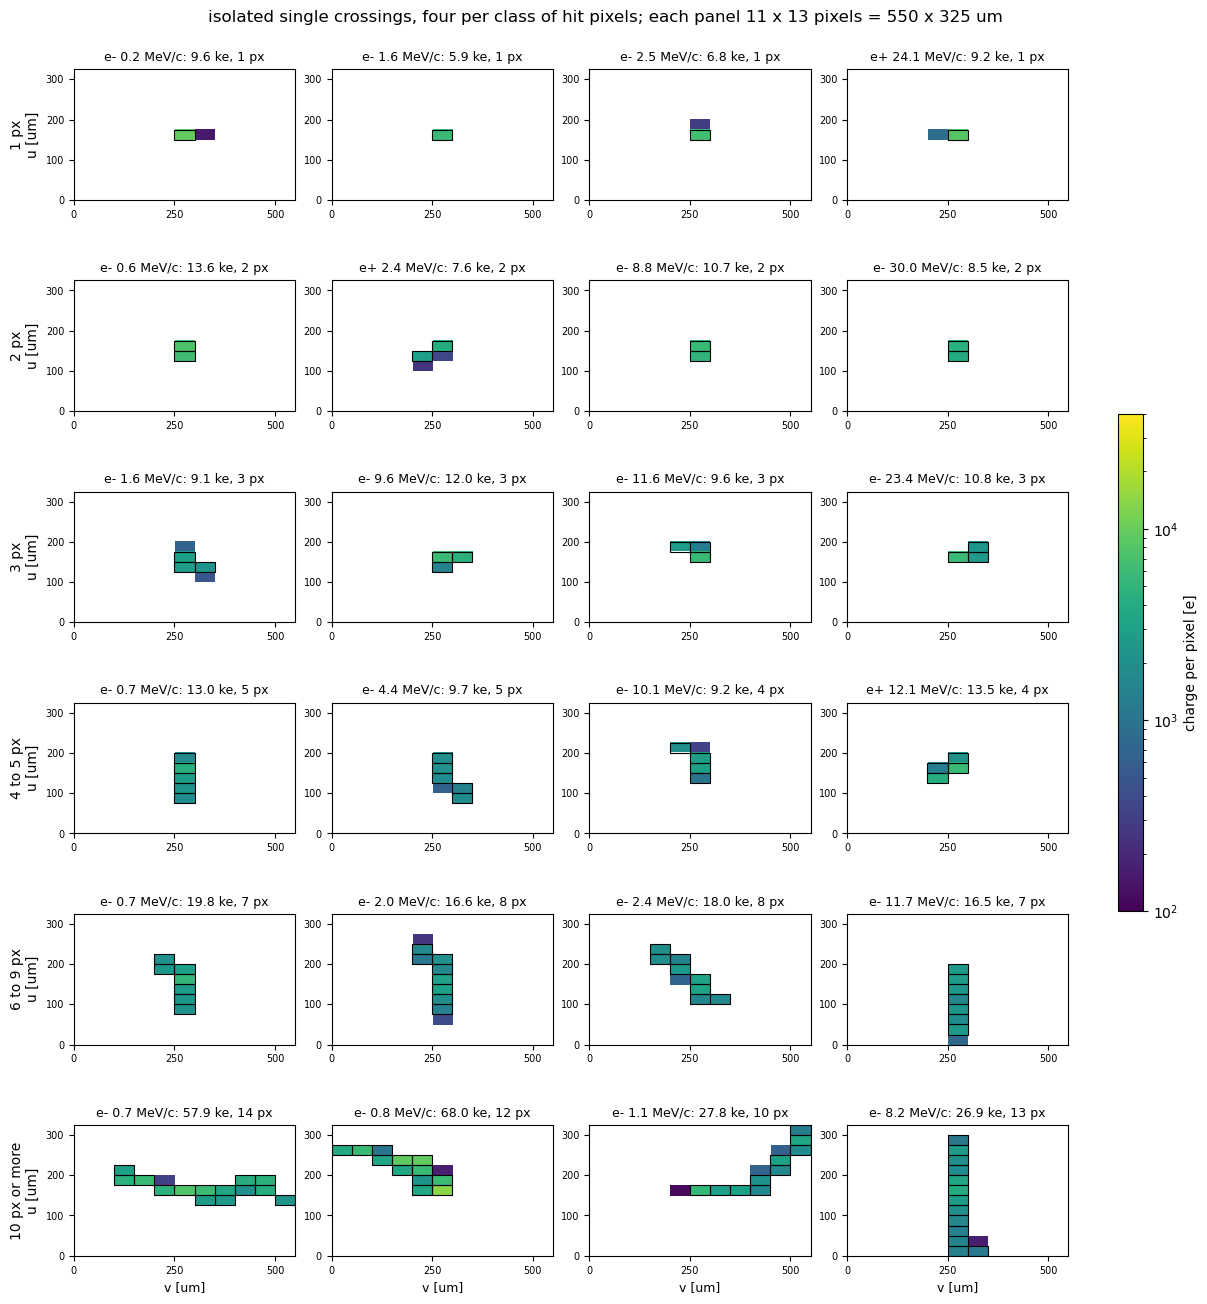

51,487 candidate crossings (counted, the only crossing of their particle, on the axis module)


In [11]:
PDG_NAME = {11: 'e-', -11: 'e+', 2212: 'proton', 22: 'photon', 2112: 'neutron'}


def pdg_name(p):
    return PDG_NAME.get(int(p), 'nucleus' if abs(int(p)) > 1000000000 else str(int(p)))


# rows sorted by plane, to find the other particles near a crossing quickly
row_plane = (row_evt * N_FACES + row_mod) * N_LAYERS + row_lay
by_plane = np.argsort(row_plane, kind='stable')
plane_sorted = row_plane[by_plane]

# the largest pixel of every crossing
o = np.lexsort((-pix_q, cross_of_row))
first_row = o[np.r_[True, np.diff(cross_of_row[o]) != 0]]          # one row per crossing, in crossing order
n_cross_all = np.bincount(cross_group, minlength=len(grp_evt))       # crossings of each group, any charge


def isolated(x, hv=SIZE_X // 2, hu=SIZE_Y // 2):
    # True when crossing x is alone in the reticle-sized window around its largest pixel
    r0 = first_row[x]
    a, b = np.searchsorted(plane_sorted, row_plane[r0], 'left'), np.searchsorted(plane_sorted, row_plane[r0], 'right')
    rows = by_plane[a:b]
    near = (np.abs(pix_iv[rows] - pix_iv[r0]) <= hv) & (np.abs(pix_iu[rows] - pix_iu[r0]) <= hu)
    own = cross_of_row[rows] == x
    return not np.any(near & ~own) and np.all(near[own])


hit_row = pix_q > THRESHOLD
n_hit_cross = np.bincount(cross_of_row[hit_row], minlength=n_cross)    # own pixels above threshold
GAL_V = 11                                                              # pixels along v shown per panel
rng = np.random.default_rng(SEED)
cand = np.flatnonzero(counted & (n_cross_all[cross_group] == 1) & (grp_mod[cross_group] == AXIS_MODULE))
CLASSES = [(1, 1), (2, 2), (3, 3), (4, 5), (6, 9), (10, 10**6)]
# the rows of crossing x are order_c[starts_c[x]:starts_c[x + 1]]
order_c = np.argsort(cross_of_row, kind='stable')
starts_c = np.searchsorted(cross_of_row[order_c], np.arange(n_cross + 1))
gallery = []
for lo, hi in CLASSES:
    got = []
    for x in rng.permutation(cand[(n_hit_cross[cand] >= lo) & (n_hit_cross[cand] <= hi)]):
        rows = order_c[starts_c[x]:starts_c[x + 1]]
        r0 = first_row[x]
        inside = (np.abs(pix_iv[rows] - pix_iv[r0]) <= GAL_V // 2) | (pix_q[rows] < SHOW_Q)
        if np.all(inside) and isolated(x):
            got.append(x)
        if len(got) == 4:
            break
    gallery.append(sorted(got, key=lambda x: C['group_root_p_MeV'][cross_group[x]]))

fig, axs = plt.subplots(len(CLASSES), 4, figsize=(12, 13), constrained_layout=True)
gnorm = LogNorm(vmin=SHOW_Q, vmax=4e4)
for (lo, hi), row_axs, xs in zip(CLASSES, axs, gallery):
    for ax in row_axs[len(xs):]:
        ax.axis('off')
    for ax, x in zip(row_axs, xs):
        r0 = first_row[x]
        iv0, iu0 = pix_iv[r0] - GAL_V // 2, pix_iu[r0] - SIZE_Y // 2
        rows = order_c[starts_c[x]:starts_c[x + 1]]
        q = pixel_image(pix_iv[rows], pix_iu[rows], pix_q[rows], iv0, iu0, GAL_V, SIZE_Y)
        ext = (0, GAL_V * PITCH_V, 0, SIZE_Y * PITCH_U)
        im = ax.imshow(np.where(q >= SHOW_Q, q, np.nan), origin='lower', interpolation='nearest', extent=ext,
                       norm=gnorm, cmap='viridis')
        for jy, jx in zip(*np.nonzero(q > THRESHOLD)):
            ax.add_patch(Rectangle((jx * PITCH_V, jy * PITCH_U), PITCH_V, PITCH_U, fill=False, ec='black', lw=0.8))
        g = cross_group[x]
        ax.set_title(f"{pdg_name(C['group_root_pdg'][g])} {C['group_root_p_MeV'][g]:.1f} MeV/c: "
                     f"{cross_q[x] / 1e3:.1f} ke, {n_hit_cross[x]} px", fontsize=9)
        ax.set_xticks([0, 250, 500])
        ax.set_yticks([0, 100, 200, 300])
        ax.tick_params(labelsize=7)
    name = f"{lo} px" if lo == hi else (f"{lo} to {hi} px" if hi < 1000 else f"{lo} px or more")
    row_axs[0].set_ylabel(name + "\nu [um]", fontsize=10)
for ax in axs[-1]:
    ax.set_xlabel('v [um]', fontsize=9)
fig.colorbar(im, ax=axs, label='charge per pixel [e]', fraction=0.025, shrink=0.6)
fig.suptitle('isolated single crossings, four per class of hit pixels; each panel 11 x 13 pixels = 550 x 325 um')
plt.show()
print(f"{len(cand):,} candidate crossings (counted, the only crossing of their particle, on the axis module)")

**Measured distributions.** Now over every counted crossing of the 20 showers, using each
crossing's own pixels only (so a neighbour's charge never adds in, and no noise).

The textbook expectation for the charge, as a rough guide: a MIP loses on average about
1.66 MeV cm²/g x 2.33 g/cm³ = 3.9 MeV/cm in silicon, so 100 um takes about 39 keV, which is about
10,500 pairs at 3.68 eV each. In a layer this thin the energy loss has a long tail to high values,
and its most probable value lies well below the mean. The Review of Particle Physics gives that
value by a formula (its equation 34.12, evaluated in the next cell): for 100 um of silicon
24.1 keV (6,538 e) at minimum ionisation, 0.62 of the mean, and 26.1 keV (7,100 e) for a fast
particle (from beta gamma 744 on, where it stops rising). We compare with the second value.

The measured most probable value is the peak of a parabola fitted to the logarithm of the counts
around the fullest bin of the charge histogram; the printout gives how much it moves with the bin
width.

The **extent** of a crossing is the diagonal of the smallest rectangle that holds its hit pixels:
`sqrt((50 um x columns)² + (25 um x rows)²)`. One hit pixel has an extent of 56 um. Its
distribution is drawn as a cumulative curve, because the extent takes only a few discrete values.

textbook mean: 3.87 MeV/cm, 38.7 keV = 10,510 e in 100 um
inputs: K 0.307075, Z/A 0.4985, 2.33 g/cm3, I 173 eV, j 0.2, density effect (4.4355, 0.2015, 2.8716, 0.14921, 3.2546, 0.14)
most probable in 100 um: 24.1 keV = 6,538 e at beta gamma 3.5 (0.62 of the mean), 26.1 keV = 7,100 e for a fast particle (0.68); constant from beta gamma 744 up


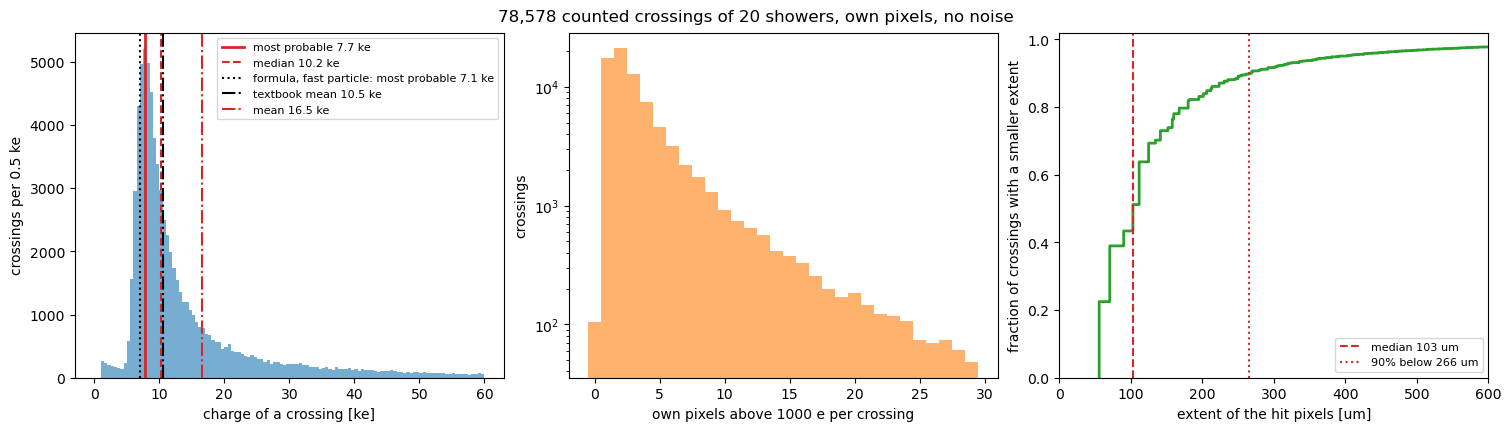

charge per crossing: most probable 7,739 e, 1.09 x the formula's value (bins of 100 to 400 e give 7,654 to 7,930 e), median 10,240 e, mean 16,550 e
own hit pixels per crossing: mean 4.15, median 3; 0.13% have none
extent: median 103 um, 90% below 266 um


In [12]:
DEDX_MIN = 1.66      # MeV cm2/g, minimum ionisation in silicon (textbook value)
RHO_SI = 2.33        # g/cm3
mip_mean_e = DEDX_MIN * RHO_SI * (THICK * 1e-4) * 1e6 / EV_PER_PAIR
print(f"textbook mean: {DEDX_MIN * RHO_SI:.2f} MeV/cm, {DEDX_MIN * RHO_SI * THICK * 1e-1:.1f} keV = {mip_mean_e:,.0f} e "
      f"in {THICK:g} um")

# most probable loss in a thin layer: RPP "Passage of particles through matter" eq. 34.12; density effect for Si
K_RPP, Z_A, I_SI, M_E, J_LVB = 0.307075, 14 / 28.0855, 173e-6, 0.51099895, 0.200   # MeV cm2/mol, -, MeV, MeV, -
C_D, X0_D, X1_D, A_D, K_D, D0_D = 4.4355, 0.2015, 2.8716, 0.14921, 3.2546, 0.14
def mpv_keV(bg, t_um=THICK):
    x, b2 = np.log10(bg), bg ** 2 / (1 + bg ** 2)
    dlt = (2 * np.log(10) * x - C_D + (A_D * (X1_D - x) ** K_D if x < X1_D else 0)) if x >= X0_D else D0_D * 10 ** (2 * (x - X0_D))
    xi = K_RPP / 2 * Z_A * RHO_SI * t_um * 1e-4 / b2                                  # MeV
    return 1e3 * xi * (np.log(2 * M_E * bg ** 2 / I_SI) + np.log(xi / I_SI) + J_LVB - b2 - dlt)
mip_mpv_e, e_min = (mpv_keV(bg) * 1e3 / EV_PER_PAIR for bg in (1e4, 3.5))     # a fast particle; minimum ionisation
print(f"inputs: K {K_RPP}, Z/A {Z_A:.4f}, {RHO_SI} g/cm3, I {I_SI * 1e6:g} eV, j {J_LVB}, density effect {C_D, X0_D, X1_D, A_D, K_D, D0_D}")
print(f"most probable in {THICK:g} um: {mpv_keV(3.5):.1f} keV = {e_min:,.0f} e at beta gamma 3.5 ({e_min / mip_mean_e:.2f} of the "
      f"mean), {mpv_keV(1e4):.1f} keV = {mip_mpv_e:,.0f} e for a fast particle ({mip_mpv_e / mip_mean_e:.2f}); constant "
      f"from beta gamma {10 ** X1_D:.0f} up")

# bounding box and 8-connected clusters of every crossing's own hit pixels
hr = np.flatnonzero(hit_row)
o = np.argsort(cross_of_row[hr], kind='stable')
hx, hv, hu = cross_of_row[hr][o], pix_iv[hr][o], pix_iu[hr][o]
ux, st = np.unique(hx, return_index=True)
n_cols = np.zeros(n_cross, np.int64)
n_rows_ = np.zeros(n_cross, np.int64)
n_cols[ux] = np.maximum.reduceat(hv, st) - np.minimum.reduceat(hv, st) + 1
n_rows_[ux] = np.maximum.reduceat(hu, st) - np.minimum.reduceat(hu, st) + 1
clu = reticles.islands(cross_of_row[hr], pix_iv[hr], pix_iu[hr], pix_q[hr], 0, PITCH_V, PITCH_U)  # gap 0: 8-connected
n_clusters = np.bincount(clu['group'], minlength=n_cross)
extent = np.hypot(n_cols * PITCH_V, n_rows_ * PITCH_U)

cq = cross_q[counted]
seen = counted & (n_hit_cross > 0)


def most_probable(x, width):
    # peak of a parabola fitted to the log of the counts in the 9 bins around the fullest one
    h, e = np.histogram(x, bins=np.arange(0, 30001, width))
    c = 0.5 * (e[1:] + e[:-1])
    j = int(np.argmax(h))
    s = slice(max(j - 4, 0), j + 5)
    p = np.polyfit(c[s], np.log(np.maximum(h[s], 1)), 2)
    return -p[1] / (2 * p[0])


mpv_all = [most_probable(cq, w) for w in (100, 200, 250, 400)]
mpv = mpv_all[1]
med_q = np.median(cq)
mean_hits = n_hit_cross[counted].mean()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
ax = axs[0]
ax.hist(cq / 1e3, bins=np.arange(0, 60.1, 0.5), histtype='stepfilled', color='C0', alpha=0.6)
ax.axvline(mpv / 1e3, color='C3', lw=2, label=f'most probable {mpv / 1e3:.1f} ke')
ax.axvline(med_q / 1e3, color='C3', ls='--', label=f'median {med_q / 1e3:.1f} ke')
ax.axvline(mip_mpv_e / 1e3, color='k', ls=':', label=f'formula, fast particle: most probable {mip_mpv_e / 1e3:.1f} ke')
ax.axvline(mip_mean_e / 1e3, color='k', ls='-.', label=f'textbook mean {mip_mean_e / 1e3:.1f} ke')
ax.axvline(cq.mean() / 1e3, color='C3', ls='-.', label=f'mean {cq.mean() / 1e3:.1f} ke')
ax.set_xlabel('charge of a crossing [ke]')
ax.set_ylabel('crossings per 0.5 ke')
ax.legend(fontsize=8)
ax = axs[1]
ax.hist(n_hit_cross[counted], bins=np.arange(-0.5, 30.5), histtype='stepfilled', color='C1', alpha=0.6)
ax.set_yscale('log')
ax.set_xlabel(f'own pixels above {THRESHOLD:g} e per crossing')
ax.set_ylabel('crossings')
ax = axs[2]
xs_ext = np.sort(extent[seen])
ax.step(xs_ext, np.arange(1, len(xs_ext) + 1) / len(xs_ext), where='post', color='C2', lw=2)
ax.axvline(np.median(extent[seen]), color='C3', ls='--', label=f'median {np.median(extent[seen]):.0f} um')
ax.axvline(np.percentile(extent[seen], 90), color='C3', ls=':', label=f'90% below {np.percentile(extent[seen], 90):.0f} um')
ax.set_xlim(0, 600)
ax.set_ylim(0, 1.02)
ax.set_xlabel('extent of the hit pixels [um]')
ax.set_ylabel('fraction of crossings with a smaller extent')
ax.legend(fontsize=8, loc='lower right')
fig.suptitle(f'{int(counted.sum()):,} counted crossings of {int(C["num_events"])} showers, own pixels, no noise')
plt.show()
print(f"charge per crossing: most probable {mpv:,.0f} e, {mpv / mip_mpv_e:.2f} x the formula's value (bins of 100 to "
      f"400 e give {min(mpv_all):,.0f} to {max(mpv_all):,.0f} e), median {med_q:,.0f} e, mean {cq.mean():,.0f} e")
print(f"own hit pixels per crossing: mean {mean_hits:.2f}, median {np.median(n_hit_cross[counted]):.0f}; "
      f"{100 * np.mean(n_hit_cross[counted] == 0):.2f}% have none")
print(f"extent: median {np.median(extent[seen]):.0f} um, 90% below {np.percentile(extent[seen], 90):.0f} um")

The most probable charge lies 9% above the formula's value for a fast particle crossing the
silicon at right angles (the printed ratio; notebook 09 finds 3% for crossings at right angles
alone). The mean lies well above the textbook mean because many paths through the silicon are
long: a crossing far from the axis is slanted (the table by distance from the axis below shows the
charge rising with the distance), and delta rays add a tail (notebook 09 measures it: in the
crossings above twice the most probable charge, the delta rays make more than half of the charge).
A few slow electrons stop in the silicon and add to the tail, but nine crossings in ten are above
1.1 MeV/c (the quantiles printed below), where the energy loss per unit length is close to its
minimum. A typical crossing lights a few pixels; a long tail lights many.

**Shapes.** Each counted crossing with at least one hit pixel is put in one of three classes:

- **spot**: 1 to 3 hit pixels;
- **thin line**: 4 or more hit pixels in one 8-connected cluster (pixels touching at an edge or a
  corner), with no more pixels than a one-pixel-wide staircase across its bounding box needs
  (`pixels <= columns + rows - 1`);
- **other**: everything else (thicker clusters, or hit pixels in two or more separate clusters).

In [13]:
n = n_hit_cross[seen]
spot = n <= 3
line = (n >= 4) & (n_clusters[seen] == 1) & (n <= n_cols[seen] + n_rows_[seen] - 1)
other = ~spot & ~line
split = other & (n_clusters[seen] > 1)
SHARES = {'spot': spot.mean(), 'thin line': line.mean(), 'other': other.mean()}
for k, v in SHARES.items():
    print(f"{k:10s} {100 * v:5.1f}%")
print(f"of 'other': {100 * split.mean():.1f}% of all crossings are split into two or more clusters, "
      f"{100 * (other & ~split).mean():.1f}% are one thick cluster")

spot        65.8%
thin line   28.0%
other        6.2%
of 'other': 3.2% of all crossings are split into two or more clusters, 2.9% are one thick cluster


Spots and thin lines make up nearly all crossings (printed above), as expected for tracks that
cross a thin layer.

**Physics check: the footprint follows the path.** A straight track through silicon of
thickness t at an angle theta to the normal moves sideways by t tan(theta). That lateral reach,
split into its parts along v and u, fixes how many pixels the track can touch: a segment of length
L on a grid of pitch p touches on average L / p + 1 pixels along that direction (it starts in one
pixel and enters a new one at each pixel edge it crosses; placed at random, it crosses L / p edges
on average), so the box around its pixels is on average L + p long. A path enters a new pixel at
each edge it crosses, along v or along u, so it touches about `1 + reach_v / 50 um + reach_u / 25 um`
pixels in all. The simulation stores, for every particle, the range of its steps in v and u
(`group_v_min_um` ... `group_u_max_um`, delta rays included). We compare that true reach with the
observed footprint, for particles that make exactly one crossing on their plane. Points on the
dashed line follow the expectation; the dots are means in bins of the true reach. The grey scale
counts the crossings in each cell (log scale, darker is more).

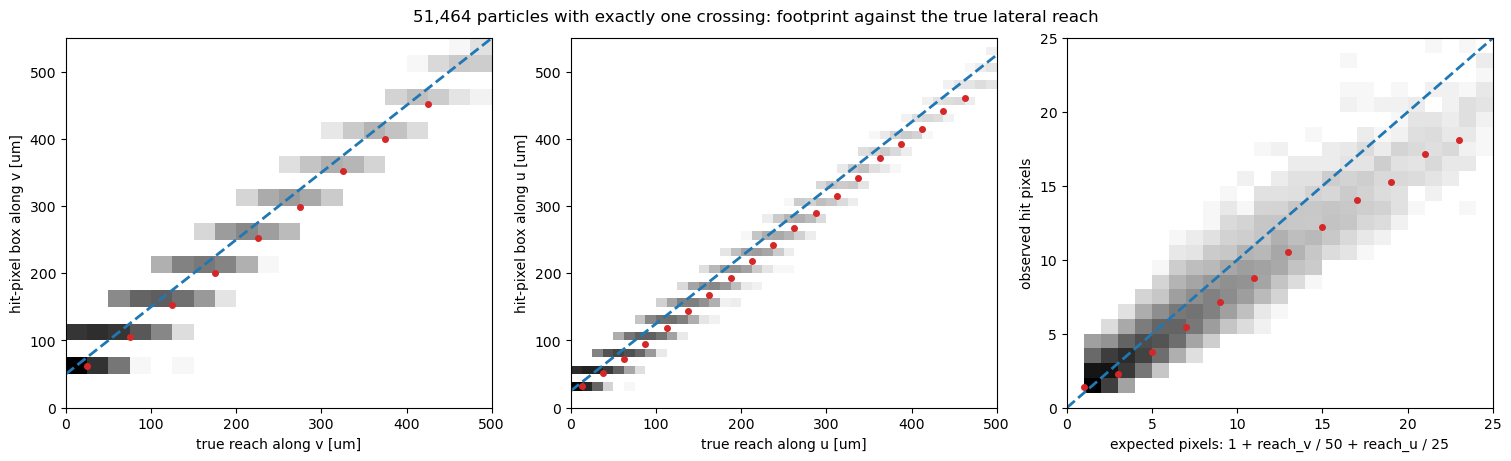

mean observed / mean expected: box along v 0.93, box along u 0.90, hit pixels 0.83
hit pixels: 0.5% exceed the expectation by more than 2, 8.0% fall short by more than 2


In [14]:
one = counted & (n_cross_all[cross_group] == 1) & (n_hit_cross > 0)
g1 = cross_group[one]
reach_v = C['group_v_max_um'][g1] - C['group_v_min_um'][g1]
reach_u = C['group_u_max_um'][g1] - C['group_u_min_um'][g1]
box_v, box_u = n_cols[one] * PITCH_V, n_rows_[one] * PITCH_U
n_exp = 1 + reach_v / PITCH_V + reach_u / PITCH_U
n_obs = n_hit_cross[one]


def panel(ax, x, y, xmax, ymax, step, expect, xlabel, ylabel):
    ax.hist2d(x, y, bins=[np.arange(0, xmax + step, step), np.arange(0, ymax + step, step)],
              norm=LogNorm(), cmap='Greys')
    xb = np.arange(0, xmax, step * 2)
    idx = np.digitize(x, xb) - 1
    avg = [np.mean(y[idx == i]) if np.count_nonzero(idx == i) > 20 else np.nan for i in range(len(xb))]
    ax.plot(xb + step, avg, 'o', color='C3', ms=4)
    xx = np.linspace(0, xmax, 10)
    ax.plot(xx, expect(xx), '--', color='C0', lw=2)
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, ymax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
panel(axs[0], reach_v, box_v, 500, 550, 25, lambda L: L + PITCH_V, 'true reach along v [um]',
      'hit-pixel box along v [um]')
panel(axs[1], reach_u, box_u, 500, 550, 12.5, lambda L: L + PITCH_U, 'true reach along u [um]',
      'hit-pixel box along u [um]')
panel(axs[2], n_exp, n_obs.astype(float), 25, 25, 1, lambda N: N,
      'expected pixels: 1 + reach_v / 50 + reach_u / 25', 'observed hit pixels')
fig.suptitle(f'{int(one.sum()):,} particles with exactly one crossing: footprint against the true lateral reach')
plt.show()
print(f"mean observed / mean expected: box along v {box_v.mean() / (reach_v + PITCH_V).mean():.2f}, "
      f"box along u {box_u.mean() / (reach_u + PITCH_U).mean():.2f}, hit pixels {n_obs.mean() / n_exp.mean():.2f}")
print(f"hit pixels: {100 * np.mean(n_obs > n_exp + 2):.1f}% exceed the expectation by more than 2, "
      f"{100 * np.mean(n_obs < n_exp - 2):.1f}% fall short by more than 2")

The box around the hit pixels runs about a tenth below the true reach plus one pitch, and the number
of hit pixels further below the expectation (printed means): a slanted track only clips the corners
of some pixels it touches, and those get too little charge to pass the threshold; at the two ends of
the track this shortens the box too. Few crossings light more pixels than expected; delta rays and
curling electrons do that.

**What the particles are.** The particle type and momentum of the counted crossings, and how the
footprint depends on the distance from the shower axis (axis module only):

In [15]:
pdg = C['group_root_pdg'][cross_group[counted]]
for p in (11, -11):
    print(f"{pdg_name(p):3s}: {100 * np.mean(pdg == p):5.1f}% of the counted crossings")
print(f"other: {100 * np.mean(~np.isin(pdg, (11, -11))):.2f}% (protons and nuclei from nuclear interactions)")
pm = C['group_root_p_MeV'][cross_group[counted]]
print("momentum [MeV/c]: 10%, 25%, 50%, 75%, 90% quantiles " + ", ".join(f"{x:.1f}" for x in np.percentile(pm, [10, 25, 50, 75, 90])))

# distance of every crossing's charge centroid from the axis
qp = np.maximum(pix_q.astype(np.float64), 0)
wq = np.bincount(cross_of_row, qp, n_cross)
cv = np.bincount(cross_of_row, qp * (pix_iv + 0.5) * PITCH_V, n_cross) / np.where(wq > 0, wq, 1)
cu = np.bincount(cross_of_row, qp * (pix_iu + 0.5) * PITCH_U, n_cross) / np.where(wq > 0, wq, 1)
cross_r_mm = np.hypot(cv, cu) * 1e-3
print("\ndistance from axis   crossings   own hit pixels (mean)   median momentum [MeV/c]   median charge [ke]")
R_FOOT = (0, 0.5, 2, 5, 20, np.inf)
FOOT = []
for lo, hi in zip(R_FOOT[:-1], R_FOOT[1:]):
    s = counted & (grp_mod[cross_group] == AXIS_MODULE) & (cross_r_mm >= lo) & (cross_r_mm < hi)
    FOOT.append(n_hit_cross[s].mean())
    print(f"{lo:5.1f} to {hi:4.1f} mm   {int(s.sum()):9,d}   {n_hit_cross[s].mean():21.2f}   "
          f"{np.median(C['group_root_p_MeV'][cross_group[s]]):23.1f}   {np.median(cross_q[s]) / 1e3:18.1f}")

e- :  62.1% of the counted crossings
e+ :  37.9% of the counted crossings
other: 0.04% (protons and nuclei from nuclear interactions)
momentum [MeV/c]: 10%, 25%, 50%, 75%, 90% quantiles 1.1, 3.0, 8.6, 25.3, 75.8

distance from axis   crossings   own hit pixels (mean)   median momentum [MeV/c]   median charge [ke]
  0.0 to  0.5 mm      15,515                    1.82                      47.5                  8.3
  0.5 to  2.0 mm      23,774                    3.22                      12.7                  9.5
  2.0 to  5.0 mm      18,405                    5.04                       6.5                 11.6
  5.0 to 20.0 mm      16,638                    6.08                       3.6                 14.0
 20.0 to  inf mm       4,203                    6.38                       1.7                 16.1


Nearly all crossings are electrons and positrons. Close to the axis they are fast, cross the
silicon nearly at right angles and light few pixels; far from it they are slow, slanted and light many.
So the number of pixels per crossing depends on where in the shower a reticle sits, even before
particles start to overlap. Section 7 comes back to this.

## 5. The readout model

A real pixel adds electronic noise and compares its charge to a threshold. The model used in the
study: every pixel gets Gaussian noise with a standard deviation of 100 e, and a pixel is **hit**
(on) when charge plus noise exceeds 1000 e. The result is the **hit map**: one bit per pixel.
`mip_counting.readout` does this; here it is applied to the whole plane of section 2, and the
same two lines of numpy are shown to give the identical map.

In [16]:
iv_lo, iu_lo = pix_iv[plane_rows].min(), pix_iu[plane_rows].min()
nv_pl = int(pix_iv[plane_rows].max() - iv_lo + 1)
nu_pl = int(pix_iu[plane_rows].max() - iu_lo + 1)
plane_img = pixel_image(pix_iv[plane_rows], pix_iu[plane_rows], pix_q[plane_rows], iv_lo, iu_lo, nv_pl, nu_pl).astype(np.float32)

hits_mod = mc.readout(plane_img[None], THRESHOLD, NOISE, np.random.default_rng(SEED))[0][0]

# the same in two lines of numpy
rng = np.random.default_rng(SEED)
noisy = plane_img + rng.standard_normal(plane_img.shape, dtype=np.float32) * np.float32(NOISE)
hits_np = noisy > THRESHOLD

assert np.array_equal(hits_mod, hits_np), "mip_counting.readout and the two numpy lines disagree"
print(f"check: mip_counting.readout equals the two numpy lines on all {plane_img.size:,} pixels of the "
      f"plane's {nv_pl} x {nu_pl} pixel box")

check: mip_counting.readout equals the two numpy lines on all 15,003,084 pixels of the plane's 2861 x 5244 pixel box


**Before and after**, on the zoom of section 2: left the charge, right the hit map. Look for
pixels that carry charge on the left but stay off on the right (their charge is below 1000 e).

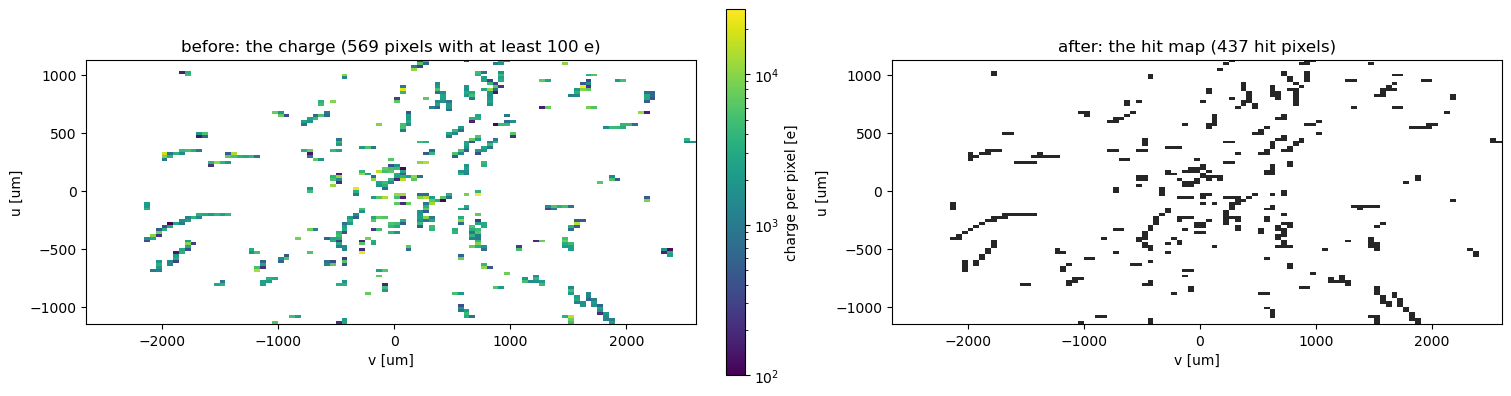

in the zoom, 132 pixels hold charge but stay off; 437 are hit


In [17]:
zv, zu = Z_IV0 - iv_lo, Z_IU0 - iu_lo
z_hit = hits_mod[zu:zu + Z_NU, zv:zv + Z_NV]
z_q = plane_img[zu:zu + Z_NU, zv:zv + Z_NV]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), constrained_layout=True)
ext = extent_um(Z_IV0, Z_IU0, Z_NV, Z_NU)
im = axs[0].imshow(np.where(z_q >= SHOW_Q, z_q, np.nan), origin='lower', interpolation='nearest', extent=ext,
                   norm=LogNorm(vmin=SHOW_Q, vmax=z_q.max()), cmap='viridis')
fig.colorbar(im, ax=axs[0], label='charge per pixel [e]', fraction=0.03)
axs[0].set_title(f'before: the charge ({np.count_nonzero(z_q >= SHOW_Q)} pixels with at least {SHOW_Q:g} e)')
axs[1].imshow(z_hit, origin='lower', interpolation='nearest', extent=ext, cmap=ListedColormap(['white', '0.15']),
              vmin=0, vmax=1)
axs[1].set_title(f'after: the hit map ({int(z_hit.sum())} hit pixels)')
for ax in axs:
    ax.set_xlabel('v [um]')
    ax.set_ylabel('u [um]')
plt.show()
print(f"in the zoom, {np.count_nonzero((z_q >= SHOW_Q) & ~z_hit)} pixels hold charge but stay off; "
      f"{int(z_hit.sum())} are hit")

**What the readout loses and adds.** Two numbers: the share of counted crossings that end up with
no hit pixel at all (they are invisible to any counter), and the number of hits that noise alone
makes in empty pixels. A noise hit needs a fluctuation of 1000 / 100 = 10 standard deviations,
which essentially never happens; the measurement confirms it. The share of invisible crossings is
measured on this plane and on every plane of the 20 showers (each with its own noise).

In [18]:
# this plane
in_plane = cross_of_row[plane_rows]
lit = hits_mod[pix_iu[plane_rows] - iu_lo, pix_iv[plane_rows] - iv_lo]
x_lit = np.bincount(in_plane, lit.astype(float), n_cross) > 0
x_plane = np.unique(in_plane)
x_plane_c = x_plane[counted[x_plane]]
lost_plane = int(np.count_nonzero(~x_lit[x_plane_c]))
empty = plane_img == 0
noise_hits = int(np.count_nonzero(hits_mod & empty))
print(f"this plane: {lost_plane} of {len(x_plane_c)} counted crossings have no hit pixel "
      f"({100 * lost_plane / len(x_plane_c):.2f}%)")
print(f"noise hits in the {int(empty.sum()):,} empty pixels of the plane's box: {noise_hits} "
      f"(expected {empty.sum() * norm.sf(THRESHOLD / NOISE):.1e})")
print(f"pixels pushed over the threshold by noise: {int(np.count_nonzero(hits_mod & (plane_img <= THRESHOLD)))}, "
      f"pushed below it: {int(np.count_nonzero(~hits_mod & (plane_img > THRESHOLD)))}")

# all planes of the 20 showers: one noise value per pixel that holds charge
KEY_OFF = 1 << 20
pkey = (row_plane * (2 * KEY_OFF) + (pix_iv + KEY_OFF)) * (2 * KEY_OFF) + (pix_iu + KEY_OFF)
upk, pinv = np.unique(pkey, return_inverse=True)
pinv = pinv.ravel()
q_px = np.bincount(pinv, pix_q.astype(np.float64), len(upk)).astype(np.float32)
hit_px = mc.readout(q_px.reshape(-1, 1, 1), THRESHOLD, NOISE, np.random.default_rng(SEED))[0].ravel()
x_lit_all = np.bincount(cross_of_row, hit_px[pinv].astype(float), n_cross) > 0
LOST_SHARE = np.mean(~x_lit_all[counted])
print(f"all planes: {int(np.count_nonzero(~x_lit_all[counted]))} of {int(counted.sum()):,} counted crossings "
      f"have no hit pixel ({100 * LOST_SHARE:.2f}%)")
print(f"median charge of those crossings: {np.median(cross_q[counted & ~x_lit_all]):,.0f} e")

this plane: 0 of 329 counted crossings have no hit pixel (0.00%)
noise hits in the 15,000,845 empty pixels of the plane's box: 0 (expected 1.1e-16)
pixels pushed over the threshold by noise: 17, pushed below it: 14
all planes: 92 of 78,578 counted crossings have no hit pixel (0.12%)
median charge of those crossings: 1,234 e


The readout loses only a small fraction of the crossings: those whose charge, although above
1000 e in total, is spread so that no single pixel reaches the threshold. Noise adds no hits in
empty pixels; it only flips a few pixels whose charge sits near the threshold. The hit map is
therefore a faithful, if coarse, picture of the crossings.

## 6. Reticles and their truth

**Tiling.** A **reticle** is a fixed block of 21 x 13 pixels (1.05 mm along v, 0.325 mm along u),
the unit whose count the edge logic would report. The grid of reticles is fixed on the pixel
grid and shifted by `offset_x = 10`, `offset_y = 6` pixels so that the shower axis falls near the
centre of one reticle. Following the docstring of `reticles.py`, pixel (iv, iu) lies in reticle

```
rv = floor((iv - offset_x) / 21)          ru = floor((iu - offset_y) / 13)
ix = iv - offset_x - 21 rv                iy = iu - offset_y - 13 ru        (its place in the reticle)
```

We tile all 20 showers this way and check that the result is exactly the reticle file
`ret_K1.npz`, whose first 20 showers are this batch.

In [19]:
KR = 1 << 16    # room for the reticle indices in one integer key


def plane_key(evt, module, layer):
    return (np.asarray(evt, np.int64) * N_FACES + module) * N_LAYERS + layer


def tile(offset_x, offset_y):
    # every pixel row of the 20 showers in its reticle; the reticle keys sort like the reticle file
    rv = np.floor_divide(pix_iv - offset_x, SIZE_X)
    ru = np.floor_divide(pix_iu - offset_y, SIZE_Y)
    ix = pix_iv - offset_x - rv * SIZE_X
    iy = pix_iu - offset_y - ru * SIZE_Y
    key = (row_plane * KR + (rv + KR // 2)) * KR + (ru + KR // 2)
    keys, ret = np.unique(key, return_inverse=True)
    ret = ret.ravel()
    S = SIZE_X * SIZE_Y
    img = np.bincount(ret * S + iy * SIZE_X + ix, pix_q.astype(np.float64), len(keys) * S)
    return {'rv': rv, 'ru': ru, 'ret': ret, 'keys': keys,
            'img': img.astype(np.float32).reshape(-1, SIZE_Y, SIZE_X)}


TL = tile(OFFSET_X, OFFSET_Y)

R1 = mc.load_reticles(need('ret_K1.npz'))        # load_reticles already applies mc.with_truth_objects
with np.load(need('ret_K1.npz')) as d:
    for k in ('rv', 'ru', 'part_pdg', 'part_p_MeV', 'input_n_groups', 'input_n_pix', 'input_event_offset',
              'plane_module', 'plane_u_axis_mm', 'plane_v_axis_mm', 'axis_module'):
        R1[k] = d[k]
assert (R1['size_x'], R1['size_y'], R1['offset_x'], R1['offset_y']) == (SIZE_X, SIZE_Y, OFFSET_X, OFFSET_Y)
assert R1['input_event_offset'][0] == 0 and R1['input_n_groups'][0] == len(grp_evt) and R1['input_n_pix'][0] == len(pix_q), \
    "the first input of ret_K1.npz is not this charges file"
assert int(R1['axis_module']) == AXIS_MODULE and R1['truth'] == 'crossings'
first20 = R1['super_evt'] < int(C['num_events'])
file_keys = (plane_key(R1['super_evt'], R1['module'], R1['layer']) * KR + (R1['rv'] + KR // 2)) * KR + (R1['ru'] + KR // 2)
assert np.array_equal(TL['keys'], file_keys[first20]), "the tiling makes other reticles than the file holds"
d_img = np.abs(TL['img'] - R1['img'][first20])
assert d_img.max() <= 1e-6 * np.abs(TL['img']).max(), f"reticle images differ by up to {d_img.max()} e"
print(f"ret_K1.npz: {len(R1['img']):,} reticles holding charge from {R1['n_events']} showers; its first "
      f"{int(C['num_events'])} showers are this batch")
print(f"check: our tiling gives the same {len(TL['keys']):,} reticles and the same images "
      f"(largest pixel difference {d_img.max():.1e} e)")
pl_sel = (R1['super_evt'] == EVENT) & (R1['module'] == AXIS_MODULE) & (R1['layer'] == LAYER)
print(f"the plane of section 2 holds charge in {int(pl_sel.sum())} reticles")

ret_K1.npz: 600,628 reticles holding charge from 200 showers; its first 20 showers are this batch
check: our tiling gives the same 59,565 reticles and the same images (largest pixel difference 0.0e+00 e)
the plane of section 2 holds charge in 219 reticles


**The grid over the hit map.** The zoom of sections 2 and 5 with its reticles; the reticle that
holds the axis is outlined in blue, and each reticle is labelled with its (rv, ru). Look at how
many hit patches straddle a red line.

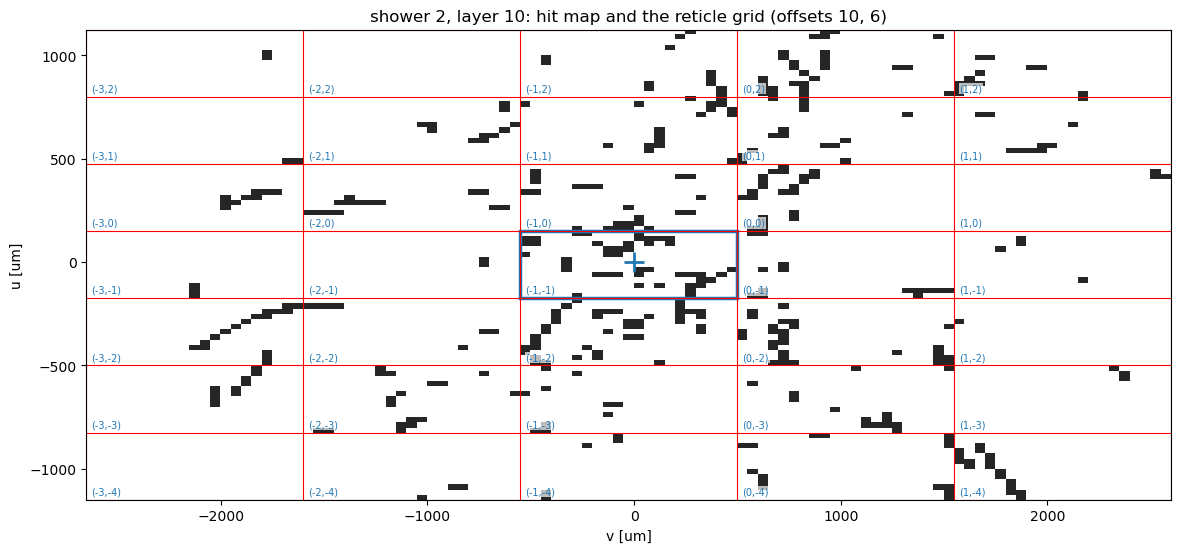

a counted crossing touches 1.31 reticles on average (pixels with any charge); 24% touch more than one


In [20]:
fig, ax = plt.subplots(figsize=(14, 6.2))
ax.imshow(z_hit, origin='lower', interpolation='nearest', extent=extent_um(Z_IV0, Z_IU0, Z_NV, Z_NU),
          cmap=ListedColormap(['white', '0.15']), vmin=0, vmax=1)
draw_grid(ax, Z_IV0, Z_IU0, Z_NV, Z_NU)
ax.add_patch(Rectangle(((OFFSET_X + RV_AXIS * SIZE_X) * PITCH_V, (OFFSET_Y + RU_AXIS * SIZE_Y) * PITCH_U),
                       SIZE_X * PITCH_V, SIZE_Y * PITCH_U, fill=False, ec='C0', lw=2.5))
for a in range(Z_NRV):
    for b in range(Z_NRU):
        rv, ru = RV_AXIS - Z_NRV // 2 + a, RU_AXIS - Z_NRU // 2 + b
        ax.text((OFFSET_X + rv * SIZE_X + 0.5) * PITCH_V, (OFFSET_Y + ru * SIZE_Y + 0.6) * PITCH_U,
                f'({rv},{ru})', fontsize=7, color='C0', va='bottom',
                bbox=dict(fc='white', ec='none', alpha=0.7, pad=0.5))
ax.plot(0, 0, '+', color='C0', ms=14, mew=2)
ax.set_xlabel('v [um]')
ax.set_ylabel('u [um]')
ax.set_title(f'shower {EVENT}, layer {LAYER}: hit map and the reticle grid (offsets {OFFSET_X}, {OFFSET_Y})')
plt.show()
cr_ret = np.bincount(np.unique(cross_of_row * len(TL['keys']) + TL['ret']) // len(TL['keys']), minlength=n_cross)
RET_PER_CROSS = cr_ret[counted].mean()
print(f"a counted crossing touches {RET_PER_CROSS:.2f} reticles on average (pixels with any charge); "
      f"{100 * np.mean(cr_ret[counted] > 1):.0f}% touch more than one")

**The truth object is the crossing.** Section 4 split each particle's pixels into crossings. Here is
a real particle on this plane that makes two crossings far apart. It is an extreme case, the
fastest of the MIP-like particles whose two crossings lie more than 1 mm apart; the printout gives
the typical ones.

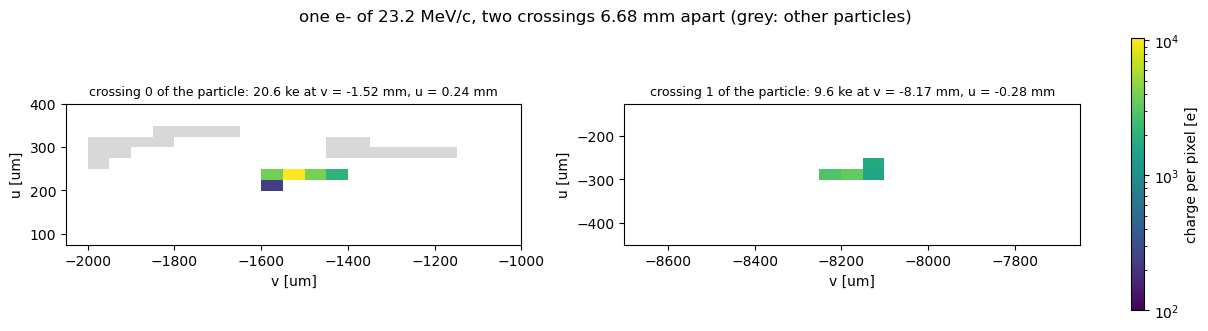

particle 8924: path in the silicon 376 um, crossings of 20,583 e and 9,647 e, 6.68 mm apart
in ret_K1.npz this particle is 2 truth objects on this plane (part_island [0, 1])
16.8% of the particles with a counted crossing make two or more on their plane; median momentum 3.9 MeV/c; with exactly two, the median distance between them is 1.57 mm


In [21]:
xp = x_plane_c                                              # counted crossings on the plane
g_of = cross_group[xp]
gs, gc = np.unique(g_of, return_counts=True)
two = gs[gc == 2]
best = None
for g in two:
    xs = xp[g_of == g]
    cen = np.c_[cv[xs], cu[xs]] * 1e-3
    dist = float(np.hypot(*(cen[0] - cen[1])))
    mip_like = np.all((cross_q[xs] > 0.5 * mip_mpv_e) & (cross_q[xs] < 3 * mip_mpv_e))
    if dist > 1.0 and mip_like and (best is None or C['group_root_p_MeV'][g] > C['group_root_p_MeV'][best[0]]):
        best = (g, xs, dist)
g2, xs2, dist2 = best
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2), constrained_layout=True)
dnorm = LogNorm(vmin=SHOW_Q, vmax=float(pix_q[cross_group[cross_of_row] == g2].max()))
for ax, x in zip(axs, xs2):
    r0 = first_row[x]
    iv0, iu0 = pix_iv[r0] - SIZE_X // 2, pix_iu[r0] - SIZE_Y // 2
    q_all = pixel_image(pix_iv[plane_rows], pix_iu[plane_rows], pix_q[plane_rows], iv0, iu0, SIZE_X, SIZE_Y)
    rows = np.flatnonzero(cross_group[cross_of_row] == g2)
    q_own = pixel_image(pix_iv[rows], pix_iu[rows], pix_q[rows], iv0, iu0, SIZE_X, SIZE_Y)
    ext = extent_um(iv0, iu0, SIZE_X, SIZE_Y)
    ax.imshow(np.where(q_all >= SHOW_Q, 1.0, np.nan), origin='lower', interpolation='nearest', extent=ext,
              cmap=ListedColormap(['0.85']))
    im = ax.imshow(np.where(q_own >= SHOW_Q, q_own, np.nan), origin='lower', interpolation='nearest', extent=ext,
                   norm=dnorm, cmap='viridis')
    ax.set_title(f'crossing {ISL["island"][x]} of the particle: {cross_q[x] / 1e3:.1f} ke at '
                 f'v = {cv[x] / 1e3:.2f} mm, u = {cu[x] / 1e3:.2f} mm', fontsize=9)
    ax.set_xlabel('v [um]')
    ax.set_ylabel('u [um]')
fig.colorbar(im, ax=axs, label='charge per pixel [e]', fraction=0.02)
fig.suptitle(f'one {pdg_name(C["group_root_pdg"][g2])} of {C["group_root_p_MeV"][g2]:.1f} MeV/c, two crossings '
             f'{dist2:.2f} mm apart (grey: other particles)')
plt.show()
in_file = (R1['part_group'] == g2) & pl_sel[R1['part_reticle']]
print(f"particle {g2}: path in the silicon {C['group_path_um'][g2]:.0f} um, crossings of "
      + " and ".join(f"{cross_q[x]:,.0f} e" for x in xs2) + f", {dist2:.2f} mm apart")
print(f"in ret_K1.npz this particle is {len(np.unique(R1['part_id'][in_file]))} truth objects on this plane "
      f"(part_island {sorted(set(R1['part_island'][in_file].tolist()))})")

# the typical case, over all planes of the 20 showers
xc = np.flatnonzero(counted & (n_cross_of_group[cross_group] == 2))
xc = xc[np.argsort(cross_group[xc], kind='stable')]
multi = n_cross_of_group >= 2
sep = np.hypot(cv[xc[0::2]] - cv[xc[1::2]], cu[xc[0::2]] - cu[xc[1::2]]) * 1e-3
print(f"{100 * multi.sum() / grp_counted.sum():.1f}% of the particles with a counted crossing make two or more on "
      f"their plane; median momentum {np.median(C['group_root_p_MeV'][multi]):.1f} MeV/c; with exactly two, "
      f"the median distance between them is {np.median(sep):.2f} mm")

The two patches are far apart and nothing in the hit map links them: a counter that looks at
pixels sees two particles, and each patch carries the charge of a full crossing. The energy
measurement needs the number of times charged particles traversed the silicon, and this particle
traversed it twice. So the truth counts crossings, not particles.

**Three truths per reticle.** A crossing can straddle a reticle edge (the grid above shows many),
so each reticle needs a rule for such crossings. With the cut at 1000 e (a crossing counts when its
total charge on the plane exceeds it), `mip_counting.truths` gives three:

- `n_in`: a crossing counts in **every** reticle where its charge inside exceeds the cut. An edge
  crossing can count twice.
- `n_own`: a crossing counts **once**, in the reticle that holds most of its charge.
- `n_frac`: a crossing is **shared** among the reticles it touches, in proportion to its charge
  in each. This is the target used in the study: it sums exactly to the number of crossings and
  stays the same when reticles are merged into larger ones.

Here they are on one real crossing that straddles an edge of two reticles.

mip_counting.truths on ret_K1.npz: 805,355 crossings above 1000 e of 814,531 truth objects

the crossing (a e- of 8.2 MeV/c) carries 9,401 e on the plane
reticle (rv, ru)   charge inside [e]   share   adds to n_in   n_own   n_frac
  ( -2,  -3)               2,114    0.22              1       0    0.225
  ( -1,  -3)               7,287    0.78              1       1    0.775
summed over the two reticles: n_in 2, n_own 1, n_frac 1.000


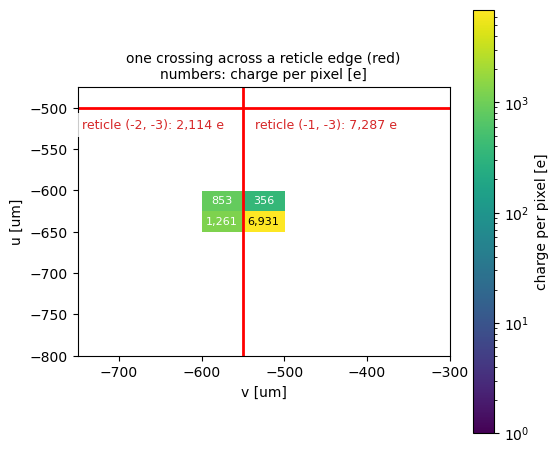

In [22]:
T1, W1, info1 = mc.truths(R1, THRESHOLD)
print(f"mip_counting.truths on ret_K1.npz: {info1['above_cut']:,} crossings above {THRESHOLD:g} e "
      f"of {info1['objects']:,} truth objects")

# rows of the file on this plane; a counted crossing split over exactly two reticles, both parts above the cut
rows_pl = np.flatnonzero(pl_sel[R1['part_reticle']])
pid = R1['part_id'][rows_pl]
u_id, u_n = np.unique(pid, return_counts=True)
n_vis = np.bincount(cross_of_row[pix_q >= SHOW_Q], minlength=n_cross)    # pixels with at least SHOW_Q
pick = None
for x in u_id[u_n == 2]:
    rr = rows_pl[pid == x]
    qq = R1['part_q'][rr].astype(np.float64)
    share = qq.max() / R1['part_q_total'][rr[0]]
    if (qq.min() > THRESHOLD and 0.55 < share < 0.8 and 0.7 * mip_mpv_e < R1['part_q_total'][rr[0]] < 3 * mip_mpv_e
            and 4 <= n_vis[x] <= 8):
        rad = np.min(R1['r_mm'][R1['part_reticle'][rr]])
        if pick is None or rad < pick[1]:
            pick = (x, rad, rr)
xs, _, rr = pick
assert cross_group[xs] == R1['part_group'][rr[0]], "part_id of the file is not the crossing index of this batch"
print(f"\nthe crossing (a {pdg_name(R1['part_pdg'][rr[0]])} of {R1['part_p_MeV'][rr[0]]:.1f} MeV/c) carries "
      f"{R1['part_q_total'][rr[0]]:,.0f} e on the plane")
print("reticle (rv, ru)   charge inside [e]   share   adds to n_in   n_own   n_frac")
for r in rr:
    ret = R1['part_reticle'][r]
    print(f"  ({R1['rv'][ret]:3d}, {R1['ru'][ret]:3d})        {R1['part_q'][r]:12,.0f}   "
          f"{R1['part_q'][r] / R1['part_q_total'][r]:5.2f}   {W1['n_in'][r]:12.0f}   {W1['n_own'][r]:5.0f}   {W1['n_frac'][r]:6.3f}")
print(f"summed over the two reticles: n_in {W1['n_in'][rr].sum():.0f}, n_own {W1['n_own'][rr].sum():.0f}, "
      f"n_frac {W1['n_frac'][rr].sum():.3f}")

# picture: the crossing's pixels with their charge, and the reticle edge between them
rows_x = np.flatnonzero(cross_of_row == xs)
NV_S, NU_S = 9, 13
iv0 = int(round(np.average(pix_iv[rows_x], weights=np.maximum(pix_q[rows_x], 0)))) - NV_S // 2
iu0 = int(round(np.average(pix_iu[rows_x], weights=np.maximum(pix_q[rows_x], 0)))) - NU_S // 2
q_own = pixel_image(pix_iv[rows_x], pix_iu[rows_x], pix_q[rows_x], iv0, iu0, NV_S, NU_S)
fig, ax = plt.subplots(figsize=(6, 5.5))
im = ax.imshow(np.where(q_own >= 1, q_own, np.nan), origin='lower', interpolation='nearest',
               extent=extent_um(iv0, iu0, NV_S, NU_S), norm=LogNorm(vmin=1, vmax=q_own.max()), cmap='viridis')
fig.colorbar(im, ax=ax, label='charge per pixel [e]')
for jy, jx in zip(*np.nonzero(q_own >= SHOW_Q)):
    ax.text((iv0 + jx + 0.5) * PITCH_V, (iu0 + jy + 0.5) * PITCH_U, f'{q_own[jy, jx]:,.0f}', ha='center',
            va='center', fontsize=8, color='white' if q_own[jy, jx] < 2000 else 'black')
for k in range(iv0, iv0 + NV_S + 1):
    if (k - OFFSET_X) % SIZE_X == 0:
        ax.axvline(k * PITCH_V, color='red', lw=2)
for k in range(iu0, iu0 + NU_S + 1):
    if (k - OFFSET_Y) % SIZE_Y == 0:
        ax.axhline(k * PITCH_U, color='red', lw=2)
for r in rr:
    ret = R1['part_reticle'][r]
    # label each reticle where it shows in the picture
    lx = np.clip((OFFSET_X + R1['rv'][ret] * SIZE_X + 0.3) * PITCH_V, iv0 * PITCH_V + 5, (iv0 + NV_S - 4) * PITCH_V)
    in_u = np.clip([OFFSET_Y + R1['ru'][ret] * SIZE_Y, OFFSET_Y + (R1['ru'][ret] + 1) * SIZE_Y], iu0, iu0 + NU_S)
    ly = (in_u[0] + 0.3) * PITCH_U if in_u[0] > iu0 else (in_u[1] - 1.0) * PITCH_U
    ax.text(lx, ly, f"reticle ({R1['rv'][ret]}, {R1['ru'][ret]}): {R1['part_q'][r]:,.0f} e",
            color='C3', fontsize=9, bbox=dict(fc='white', ec='none', alpha=0.8))
ax.set_xlabel('v [um]')
ax.set_ylabel('u [um]')
ax.set_title('one crossing across a reticle edge (red)\nnumbers: charge per pixel [e]', fontsize=10)
plt.show()

The table shows the three rules on this crossing: `n_in` counts it in both reticles (both parts pass
the cut), `n_own` gives it only to the reticle with the larger part, and `n_frac` splits it by its
charge so that the two shares add to one.

**Checks.** We compute the three truths again with a few explicit lines of numpy, from the charges
file, our own tiling and our own crossings, and require:

1. on every plane of the 20 showers, the sums of `n_frac` and of `n_own` over the reticles of
   mip_counting's result equal the number of counted crossings on that plane (from section 4);
2. reticle by reticle, our `n_in`, `n_own` and `n_frac` equal those of `mip_counting.truths`.

The first check does not depend on where the grid is placed (a sum over a plane is the same for
any tiling); the second one does.

In [23]:
def explicit_truths(tl, cut=THRESHOLD):
    # n_in, n_own, n_frac per reticle of the tiling tl, from the crossings of section 4
    n_ret = len(tl['keys'])
    key = tl['ret'] * n_cross + cross_of_row
    ukey, inv = np.unique(key, return_inverse=True)
    part_q = np.bincount(inv.ravel(), pix_q.astype(np.float64), len(ukey))   # crossing's charge in the reticle
    part_ret, part_x = ukey // n_cross, ukey % n_cross
    is_counted = cross_q[part_x] > cut
    frac = np.zeros(len(ukey))
    frac[is_counted] = np.clip(part_q[is_counted] / cross_q[part_x[is_counted]], 0, 1)
    order = np.lexsort((part_ret, -part_q, part_x))                          # per crossing: largest part first
    first = order[np.r_[True, np.diff(part_x[order]) != 0]]
    return {'n_in': np.bincount(part_ret, (part_q > cut).astype(float), n_ret),
            'n_own': np.bincount(part_ret[first], is_counted[first].astype(float), n_ret),
            'n_frac': np.bincount(part_ret, frac, n_ret)}


# check 1: per plane, mip_counting's sums equal the counted crossings
ret_plane = plane_key(R1['super_evt'], R1['module'], R1['layer'])
cross_plane = plane_key(grp_evt, grp_mod, grp_lay)[cross_group]
planes = np.unique(cross_plane[counted])
n_true_plane = np.bincount(np.searchsorted(planes, cross_plane[counted]), minlength=len(planes))
on = first20 & np.isin(ret_plane, planes)
assert np.all(np.isin(ret_plane[first20], planes) | (T1['n_own'][first20] == 0))
pos = np.searchsorted(planes, ret_plane[on])
s_frac = np.bincount(pos, T1['n_frac'][on], len(planes))
s_own = np.bincount(pos, T1['n_own'][on], len(planes))
assert np.array_equal(s_own, n_true_plane), "n_own does not sum to the counted crossings of a plane"
assert np.allclose(s_frac, n_true_plane, rtol=0, atol=1e-6 * n_true_plane.max()), "n_frac does not sum to them"
print(f"check 1: on all {len(planes)} planes holding a counted crossing in the {int(C['num_events'])} showers, "
      f"n_own and n_frac sum to the counted crossings ({int(n_true_plane.sum()):,} in all; largest n_frac "
      f"difference {np.abs(s_frac - n_true_plane).max():.1e})")

# check 2: reticle by reticle against mip_counting.truths
TLc = tile(OFFSET_X, OFFSET_Y)
mine = explicit_truths(TLc)
allk = np.union1d(TLc['keys'], file_keys[first20])
for name, tol in (('n_frac', 1e-5), ('n_own', 0), ('n_in', 0)):
    a = np.zeros(len(allk))
    b = np.zeros(len(allk))
    a[np.searchsorted(allk, TLc['keys'])] = mine[name]
    b[np.searchsorted(allk, file_keys[first20])] = T1[name][first20]
    bad = np.abs(a - b) > tol
    assert not bad.any(), (f"{name} differs from mip_counting.truths in {int(bad.sum()):,} of {len(allk):,} "
                           f"reticles (largest difference {np.abs(a - b).max():.3f})")
    print(f"check 2: {name} equals mip_counting.truths in all {len(allk):,} reticles "
          f"(largest difference {np.abs(a - b).max():.1e})")

check 1: on all 601 planes holding a counted crossing in the 20 showers, n_own and n_frac sum to the counted crossings (78,578 in all; largest n_frac difference 8.6e-08)
check 2: n_frac equals mip_counting.truths in all 59,565 reticles (largest difference 8.5e-08)
check 2: n_own equals mip_counting.truths in all 59,565 reticles (largest difference 0.0e+00)
check 2: n_in equals mip_counting.truths in all 59,565 reticles (largest difference 0.0e+00)


## 7. What density does

Now all 200 showers of `ret_K1.npz`, and `ret_K8.npz`, where every 8 showers are stacked on top of
each other. Stacking raises the density of crossings eight-fold at every depth and
distance from the axis, with the same mix of particles. It is a way to reach the densities of a
higher-energy core, not a shower of 400 GeV.

The reticle files store only reticles that hold charge. The map below counts the empty ones too:
for each layer and each ring of distance from the axis, the summed `n_frac` divided by the number
of reticles of the grid whose centre lies in the ring (counted with `reticles.count_within`), so it
is the mean number of crossings per reticle. Look for where the density peaks and how fast it falls
with distance.

K1: 600,628 reticles holding charge; noise hits in their 159,080,375 empty pixels: 0


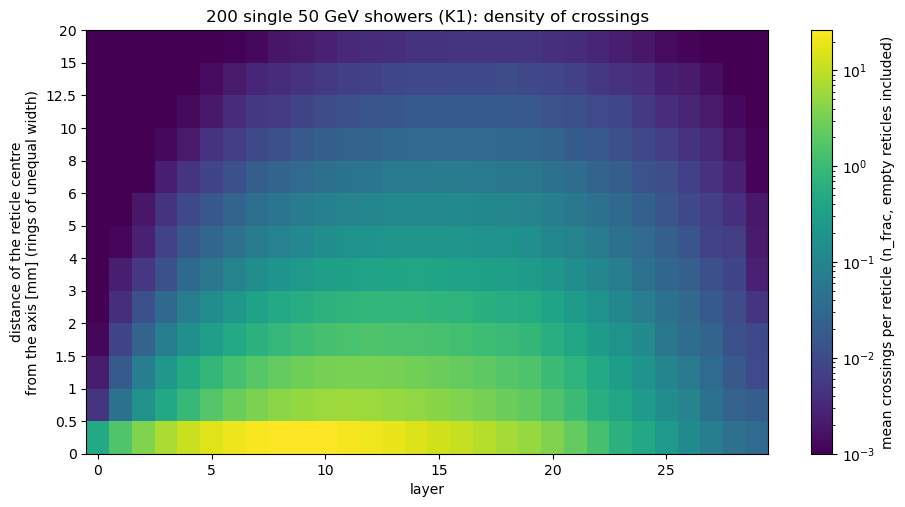

highest mean density: 26.3 crossings per reticle, layer 9, 0 to 0.5 mm
  ring 0 to 0.5 mm: at most 26.318 per reticle (layer 9)
  ring 3 to 4 mm: at most 0.391 per reticle (layer 14)
  ring 6 to 8 mm: at most 0.067 per reticle (layer 15)
  ring 10 to 12.5 mm: at most 0.017 per reticle (layer 17)
share of the crossings beyond 20 mm or on other modules (not in the map): 0.055


In [24]:
assert np.allclose(R1['plane_u_axis_mm'][R1['plane_module'] == AXIS_MODULE], 0) and \
       np.allclose(R1['plane_v_axis_mm'][R1['plane_module'] == AXIS_MODULE], 0), "the axis is not at u = v = 0"
nf1 = T1['n_frac']
hits1 = mc.readout(R1['img'], THRESHOLD, NOISE, np.random.default_rng((SEED, 0)))[0]
nh1 = hits1.sum(axis=(1, 2))
NOISE_HITS_K1 = int(np.count_nonzero(hits1 & (R1['img'] == 0)))
print(f"K1: {len(nf1):,} reticles holding charge; noise hits in their {int(np.count_nonzero(R1['img'] == 0)):,} "
      f"empty pixels: {NOISE_HITS_K1}")

R_EDGES = np.array([0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10, 12.5, 15, 20])
lu, lv = SIZE_Y * PITCH_U * 1e-3, SIZE_X * PITCH_V * 1e-3            # reticle size [mm]
ou, ov = OFFSET_Y * PITCH_U * 1e-3, OFFSET_X * PITCH_V * 1e-3        # grid origin [mm]
n_grid = np.diff(np.r_[0, reticles.count_within(0.0 - ou, 0.0 - ov, R_EDGES[1:], lu, lv)])
m7 = R1['module'] == AXIS_MODULE
Hn, _, _ = np.histogram2d(R1['layer'][m7], R1['r_mm'][m7], bins=[np.arange(N_LAYERS + 1) - 0.5, R_EDGES],
                          weights=nf1[m7])
density = Hn / (R1['n_super_events'] * n_grid[None, :])

fig, ax = plt.subplots(figsize=(11, 5.5))
ring = np.arange(len(R_EDGES))          # every ring drawn with the same height
m = ax.pcolormesh(np.arange(N_LAYERS + 1) - 0.5, ring, np.where(density > 0, density, np.nan).T,
                  norm=LogNorm(vmin=1e-3, vmax=density.max()), cmap='viridis')
fig.colorbar(m, ax=ax, label='mean crossings per reticle (n_frac, empty reticles included)')
ax.set_yticks(ring)
ax.set_yticklabels([f'{x:g}' for x in R_EDGES])
ax.set_xlabel('layer')
ax.set_ylabel('distance of the reticle centre\nfrom the axis [mm] (rings of unequal width)')
ax.set_title(f'{R1["n_super_events"]} single 50 GeV showers (K1): density of crossings')
plt.show()
iL, iR = np.unravel_index(np.argmax(density), density.shape)
print(f"highest mean density: {density[iL, iR]:.1f} crossings per reticle, layer {iL}, "
      f"{R_EDGES[iR]:g} to {R_EDGES[iR + 1]:g} mm")
for lo in (0, 3, 6, 10):
    j = np.searchsorted(R_EDGES, lo)
    print(f"  ring {R_EDGES[j]:g} to {R_EDGES[j + 1]:g} mm: at most {density[:, j].max():.3f} per reticle "
          f"(layer {int(np.argmax(density[:, j]))})")
beyond = (~m7) | (R1['r_mm'] >= R_EDGES[-1])
print(f"share of the crossings beyond {R_EDGES[-1]:g} mm or on other modules (not in the map): "
      f"{nf1[beyond].sum() / nf1.sum():.3f}")

The density is highest on the axis near the shower maximum (the printed layer) and falls by orders
of magnitude within a few millimetres. A single 50 GeV shower is therefore sparse almost everywhere: the next
table shows how the reticles and the crossings divide by the number of crossings in a reticle
(`n_frac` rounded to an integer), in wide bins (groups of the bins used from here on), for single
showers and for stacks of eight.

In [25]:
R8 = mc.load_reticles(need('ret_K8.npz'))
T8, W8, info8 = mc.truths(R8, THRESHOLD)
nf8 = T8['n_frac']
hits8 = mc.readout(R8['img'], THRESHOLD, NOISE, np.random.default_rng((SEED, 1)))[0]
nh8 = hits8.sum(axis=(1, 2))
del hits8
r_mm8, layer8, module8 = R8['r_mm'], R8['layer'], R8['module']
R8_n, n_stacks = len(R8['img']), R8['n_super_events']
assert R8['overlay'] == 8
del R8                                   # the K8 images are not needed further
print(f"K8: {n_stacks} stacks of 8 showers, {R8_n:,} reticles holding charge, {info8['above_cut']:,} counted crossings")

BINS = [(0, 0, '0'), (1, 1, '1'), (2, 5, '2 to 5'), (6, 20, '6 to 20'), (21, 10**9, 'above 20')]
TABLE = {}
print("\ncrossings in the reticle (n_frac rounded)  " + "".join(f"{b[2]:>10s}" for b in BINS))
for tag, nf in (('K1', nf1), ('K8', nf8)):
    k = np.rint(nf)
    sr = [np.mean((k >= lo) & (k <= hi)) for lo, hi, _ in BINS]
    sc = [nf[(k >= lo) & (k <= hi)].sum() / nf.sum() for lo, hi, _ in BINS]
    TABLE[tag] = (sr, sc)
    print(f"{tag}: share of the reticles holding charge  " + "".join(f"{100 * x:9.1f}%" for x in sr))
    print(f"{tag}: share of all crossings                " + "".join(f"{100 * x:9.1f}%" for x in sc))
print(f"\ndensest reticle: K1 {nf1.max():.0f} crossings, K8 {nf8.max():.0f} crossings")

K8: 25 stacks of 8 showers, 365,407 reticles holding charge, 805,355 counted crossings

crossings in the reticle (n_frac rounded)           0         1    2 to 5   6 to 20  above 20
K1: share of the reticles holding charge       25.7%     57.0%     14.7%      2.2%      0.5%
K1: share of all crossings                      4.1%     40.1%     28.2%     15.1%     12.5%
K8: share of the reticles holding charge       24.8%     52.1%     17.5%      4.3%      1.3%
K8: share of all crossings                      2.4%     22.4%     21.1%     19.4%     34.8%

densest reticle: K1 96 crossings, K8 441 crossings


In single showers most reticles that hold charge hold one crossing, but a sizeable share of the
crossings lives in the few dense reticles of the core. Stacking eight showers moves the crossings
toward the dense bins. ("0" collects reticles holding only small parts of crossings that sit
mostly elsewhere.)

**A gallery of reticles** from single showers, with about 1, 3, 8, 20 and 50 crossings. The reticle
files do not keep each particle's pixels, so the colours of section 3 are not available. Left: the
charge, with a white dot on the pixel where each counted crossing left most of its charge inside
the reticle. Right: the hit map after noise. Look at how the hit pixels go from separate spots to
a few large merged patches.

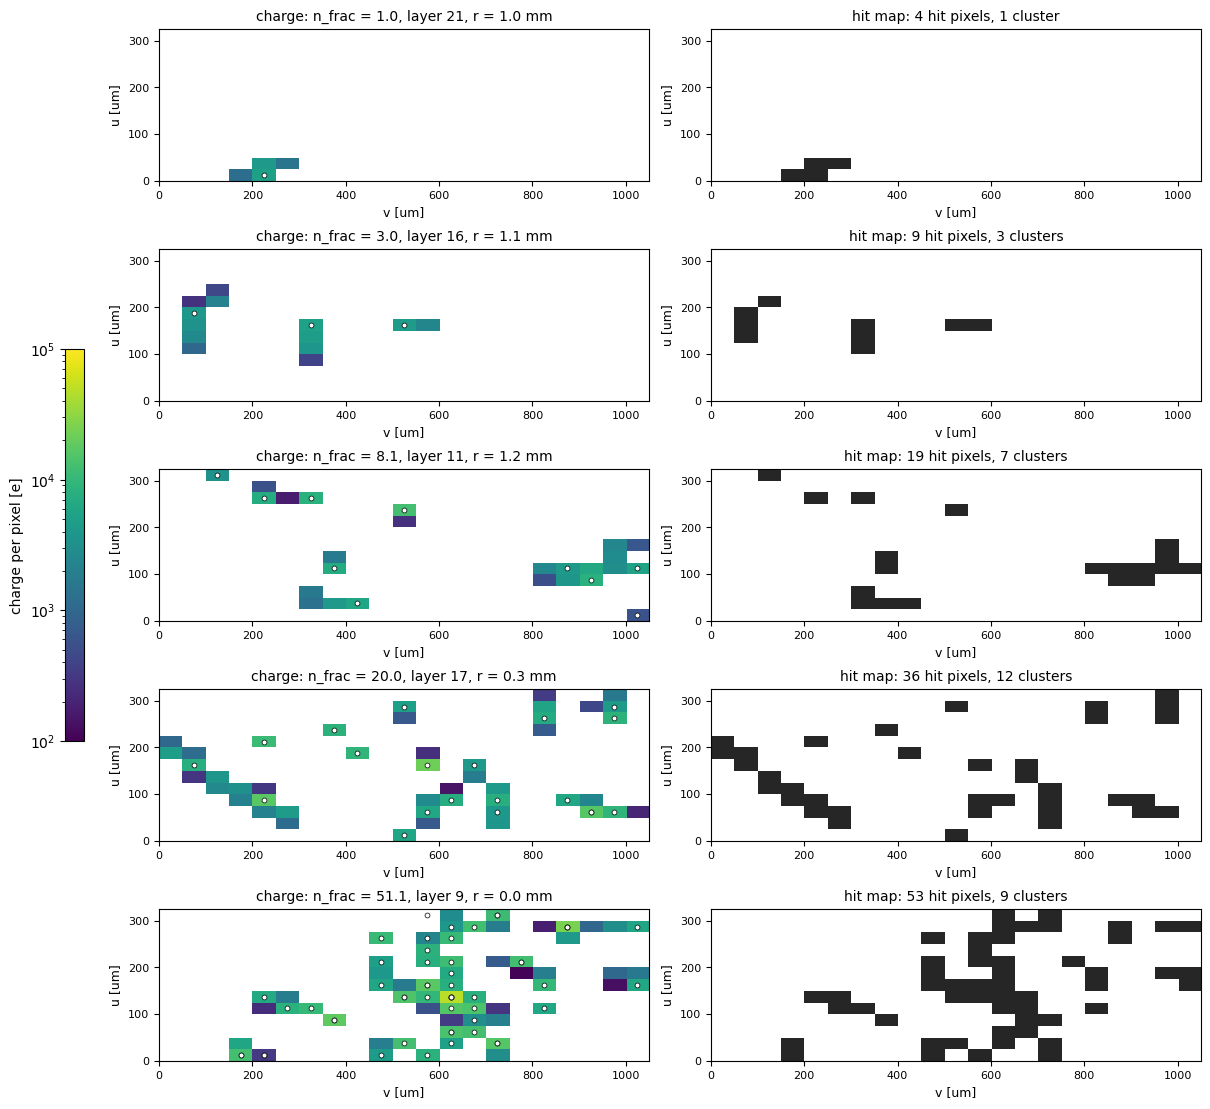

target   1: n_frac   1.00,   4 hit pixels,  1 cluster  (8-connected), 4.0 hit pixels per crossing
target   3: n_frac   3.00,   9 hit pixels,  3 clusters (8-connected), 3.0 hit pixels per crossing
target   8: n_frac   8.06,  19 hit pixels,  7 clusters (8-connected), 2.4 hit pixels per crossing
target  20: n_frac  19.98,  36 hit pixels, 12 clusters (8-connected), 1.8 hit pixels per crossing
target  50: n_frac  51.06,  53 hit pixels,  9 clusters (8-connected), 1.0 hit pixels per crossing


In [26]:
TARGETS = (1, 3, 8, 20, 50)
rng = np.random.default_rng(SEED)
k1 = np.rint(nf1)
picks = []
for t in TARGETS:
    c = np.flatnonzero(m7 & (np.abs(nf1 - t) < max(0.05, 0.03 * t)))     # close to the target
    if len(c) == 0:
        c = np.flatnonzero(m7 & (np.abs(nf1 - t) == np.min(np.abs(nf1[m7] - t))))
    picks.append(int(rng.choice(c)))
_, cl_g = mc.clusters(hits1[picks], PITCH_V, PITCH_U)
n_cl_g = np.bincount(cl_g['reticle'], minlength=len(picks))
counted_row = R1['part_q_total'] > THRESHOLD

fig, axs = plt.subplots(len(picks), 2, figsize=(12, 11), constrained_layout=True)
axs = axs.T
ext = (0, SIZE_X * PITCH_V, 0, SIZE_Y * PITCH_U)
for j, i in enumerate(picks):
    img = R1['img'][i]
    im = axs[0, j].imshow(np.where(img >= SHOW_Q, img, np.nan), origin='lower', interpolation='nearest',
                          extent=ext, norm=LogNorm(vmin=SHOW_Q, vmax=1e5), cmap='viridis')
    rr = np.flatnonzero((R1['part_reticle'] == i) & counted_row)
    axs[0, j].plot((R1['part_iv'][rr] + 0.5) * PITCH_V, (R1['part_iu'][rr] + 0.5) * PITCH_U, 'o', ms=3.5,
                   mfc='white', mec='black', mew=0.5)
    axs[0, j].set_title(f'charge: n_frac = {nf1[i]:.1f}, layer {R1["layer"][i]}, r = {R1["r_mm"][i]:.1f} mm', fontsize=10)
    axs[1, j].imshow(hits1[i], origin='lower', interpolation='nearest', extent=ext,
                     cmap=ListedColormap(['white', '0.15']), vmin=0, vmax=1)
    axs[1, j].set_title(f'hit map: {nh1[i]} hit pixels, {n_cl_g[j]} cluster' + ('s' if n_cl_g[j] != 1 else ''),
                        fontsize=10)
    for ax in axs[:, j]:
        ax.set_xlabel('v [um]', fontsize=9)
        ax.set_ylabel('u [um]', fontsize=9)
        ax.tick_params(labelsize=8)
fig.colorbar(im, ax=axs[0, :], label='charge per pixel [e]', fraction=0.04, shrink=0.5, location='left')
plt.show()
for j, i in enumerate(picks):
    print(f"target {TARGETS[j]:3d}: n_frac {nf1[i]:6.2f}, {nh1[i]:3d} hit pixels, {n_cl_g[j]:2d} cluster{'s' if n_cl_g[j] != 1 else ' '} (8-connected), "
          f"{nh1[i] / nf1[i]:.1f} hit pixels per crossing")

**The key curve: hit pixels against crossings.** For bins of the number of crossings per reticle
(`n_frac`; one bin per integer up to 10, wider bins above; the printout uses the bins of notebook
11), the mean number of hit pixels and the band holding the central 68% of the reticles, for
single showers (K1) and stacks of eight (K8).

Two reference lines help to read it:

- the grey line is the mean number of pixels a crossing lights on its own (section 4) times the
  number of crossings: what one would expect if every crossing were average and none overlapped;
- the dashed line, from the 20 showers of this batch without noise, adds up reticle by reticle the
  pixels each crossing would light if it were alone. It knows which crossings sit in dense reticles
  but ignores overlaps. Where the measured curve falls below it, hit pixels of different crossings
  merge.

The dotted line is the 273 pixels of a reticle. Look at where each curve leaves the grey line.

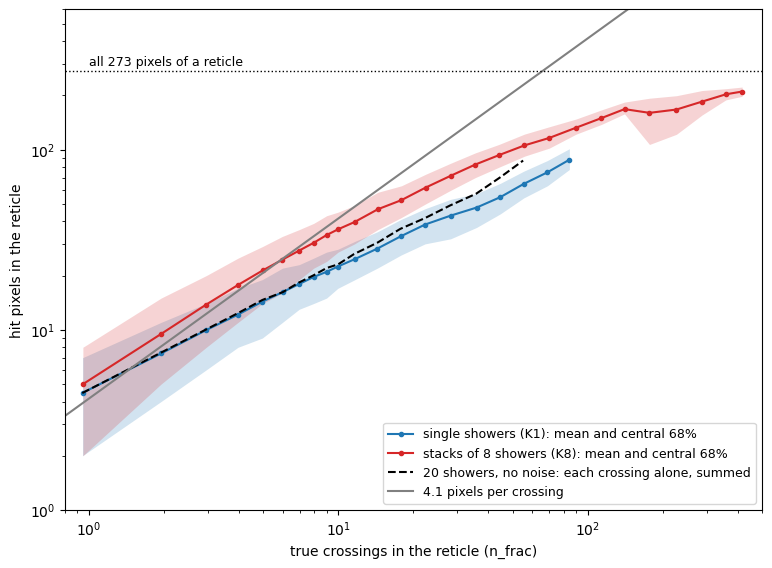

own pixels per crossing (section 4): 4.15
true count  K1: hits per reticle  per crossing  K8: hits per reticle  per crossing
         1                   4.5          4.73                   5.0          5.27
         2                   7.4          3.79                   9.5          4.87
         3                  10.0          3.37                  13.8          4.67
       4-5                  13.0          2.99                  19.2          4.39
       6-8                  17.5          2.60                  26.9          3.97
      9-12                  22.7          2.23                  36.5          3.57
     13-20                  30.4          1.91                  49.1          3.08
     21-40                  42.6          1.51                  70.7          2.54
     41-80                  61.1          1.18                 103.0          1.90
       81+                                                     162.2          0.93
reticles with 3 crossings lie at a median 1.4

In [27]:
# bins of n_frac: one per integer up to 10, then about four per factor of ten
N_EDGES = np.r_[np.arange(0.5, 10.6, 1.0), 13, 16, 20, 25, 32, 40, 50, 63, 80, 100, 126, 160, 200, 250, 320, 400, 500]


def profile(nf, nh, min_n=10):
    # per bin of n_frac: (mean n_frac, mean hits, 16% and 84% quantiles of hits, reticles)
    b = np.digitize(nf, N_EDGES) - 1
    out = []
    for j in range(len(N_EDGES) - 1):
        s = b == j
        if s.sum() >= min_n:
            out.append((nf[s].mean(), nh[s].mean(), *np.percentile(nh[s], [16, 84]), s.sum()))
    return np.array(out)


# the 20 showers without noise: pixels each crossing lights on its own, summed per reticle
nf20 = mine['n_frac']
own20 = np.bincount(TLc['ret'][hit_row], minlength=len(TLc['keys']))
act20 = (TLc['img'] > THRESHOLD).sum(axis=(1, 2))
P1, P8 = profile(nf1, nh1), profile(nf8, nh8)
Pown = profile(nf20, own20)

fig, ax = plt.subplots(figsize=(9, 6.5))
for P, col, lab in ((P1, 'C0', 'single showers (K1)'), (P8, 'C3', 'stacks of 8 showers (K8)')):
    ax.fill_between(P[:, 0], P[:, 2], P[:, 3], color=col, alpha=0.2, lw=0)
    ax.plot(P[:, 0], P[:, 1], 'o-', color=col, ms=3, label=lab + ': mean and central 68%')
ax.plot(Pown[:, 0], Pown[:, 1], '--', color='k', label=f'{int(C["num_events"])} showers, no noise: '
        'each crossing alone, summed')
xx = np.array([0.8, 500])
ax.plot(xx, mean_hits * xx, '-', color='0.5', lw=1.5, label=f'{mean_hits:.1f} pixels per crossing')
ax.axhline(SIZE_X * SIZE_Y, color='k', ls=':', lw=1)
ax.text(1.0, SIZE_X * SIZE_Y * 1.08, f'all {SIZE_X * SIZE_Y} pixels of a reticle', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.8, 500)
ax.set_ylim(1, 600)
ax.set_xlabel('true crossings in the reticle (n_frac)')
ax.set_ylabel('hit pixels in the reticle')
ax.legend(fontsize=9, loc='lower right')
plt.show()


def in_bin(k, lo, hi):
    # the reticles whose rounded n_frac k lies in the bin lo to hi of mc.TRUTH_BINS (hi None: no upper end)
    return (k >= lo) & ((k <= hi) if hi is not None else True)


# the printout: the bins of notebook 11 (n_frac rounded), bins with fewer than 10 reticles left out
k1, k8 = np.rint(nf1), np.rint(nf8)
print(f"own pixels per crossing (section 4): {mean_hits:.2f}")
print("true count  K1: hits per reticle  per crossing  K8: hits per reticle  per crossing")
HPC = {'K1': {}, 'K8': {}}               # hit pixels per crossing: sum of n_hits / sum of n_frac, per bin
for lo, hi in mc.TRUTH_BINS[1:]:
    lab = mc._bins_label(lo, hi)
    cols = []
    for tag, k, nf, nh in (('K1', k1, nf1, nh1), ('K8', k8, nf8, nh8)):
        s = in_bin(k, lo, hi)
        if s.sum() >= 10:
            HPC[tag][lab] = nh[s].sum() / nf[s].sum()
            cols.append(f"{nh[s].mean():20.1f}  {HPC[tag][lab]:12.2f}")
        else:
            cols.append(f"{'':20s}  {'':12s}")
    print(f"{lab:>10s}  {cols[0]}  {cols[1]}")
for lo, hi in ((3, 3), (9, 12)):
    s1 = in_bin(k1, lo, hi) & m7
    s8 = in_bin(k8, lo, hi) & (module8 == AXIS_MODULE)
    print(f"reticles with {mc._bins_label(lo, hi).replace('-', ' to ')} crossings lie at a median "
          f"{np.median(R1['r_mm'][s1]):.2f} mm from the axis in K1, {np.median(r_mm8[s8]):.2f} mm in K8")

At one crossing per reticle the single-shower curve sits near the grey line. Above that it bends
down long before the reticle fills, and the dashed line, which has no merging at all, bends almost
the same way. So at low and moderate density the bend comes mostly from which crossings populate
dense reticles: they lie near the axis, where particles are fast and light fewer pixels each
(section 4). Merging adds to it as the density grows (the column 'merged away' of the table
further down in this section). The K8 curve lies above the K1 curve at the same number of
crossings, because in the
stacks that number is reached farther from the axis, where crossings light more pixels.

The stacks of eight also isolate merging cleanly: at the same place in the shower they hold the
same mix of particles at eight times the density, so any drop in pixels per crossing from K1 to
K8 at the same distance from the axis is merging:

In [28]:
print("distance from axis   K1: crossings per reticle   pixels per crossing   K8: crossings per reticle   pixels per crossing   K8 / K1")
MERGE = []
for lo, hi in ((0, 0.5), (0.5, 1), (1, 2), (2, 5), (5, 20)):
    s1 = m7 & (R1['r_mm'] >= lo) & (R1['r_mm'] < hi)
    s8 = (module8 == AXIS_MODULE) & (r_mm8 >= lo) & (r_mm8 < hi)
    p1, p8 = nh1[s1].sum() / nf1[s1].sum(), nh8[s8].sum() / nf8[s8].sum()
    MERGE.append((lo, hi, p1, p8))
    print(f"{lo:4.1f} to {hi:4.1f} mm   {nf1[s1].mean():25.2f}   {p1:19.2f}   {nf8[s8].mean():25.2f}   "
          f"{p8:19.2f}   {p8 / p1:7.2f}")

distance from axis   K1: crossings per reticle   pixels per crossing   K8: crossings per reticle   pixels per crossing   K8 / K1
 0.0 to  0.5 mm                       14.39                  1.62                       88.79                  1.07      0.66
 0.5 to  1.0 mm                        3.87                  2.81                       21.56                  2.43      0.86
 1.0 to  2.0 mm                        2.14                  3.36                       10.47                  3.09      0.92
 2.0 to  5.0 mm                        0.98                  4.90                        2.39                  4.79      0.98
 5.0 to 20.0 mm                        0.73                  6.05                        0.85                  6.03      1.00


Close to the axis, where single showers already hold several crossings per reticle, stacking eight
showers cuts the pixels per crossing substantially; far from the axis, where even eight showers
leave reticles sparse, it hardly changes them. Merging is a high-density effect, while the shape of
the curve at low density is set by the particles.

**Clusters merge long before pixels do.** A counter cannot see which particle lit a pixel. What it
can see are **clusters**: sets of hit pixels that touch at an edge or a corner. Two crossings can
keep every one of their own pixels and still touch, and then the hit map shows one cluster where
there were two. So we repeat the comparison for clusters, on the 20 showers of this batch without
noise: for every reticle, the number of clusters its crossings would make if each were alone
(summed over the crossings), against the number of clusters in the real hit map. The table gives the
same comparison for hit pixels next to it. Look at how early the measured cluster curve leaves the
dashed one.

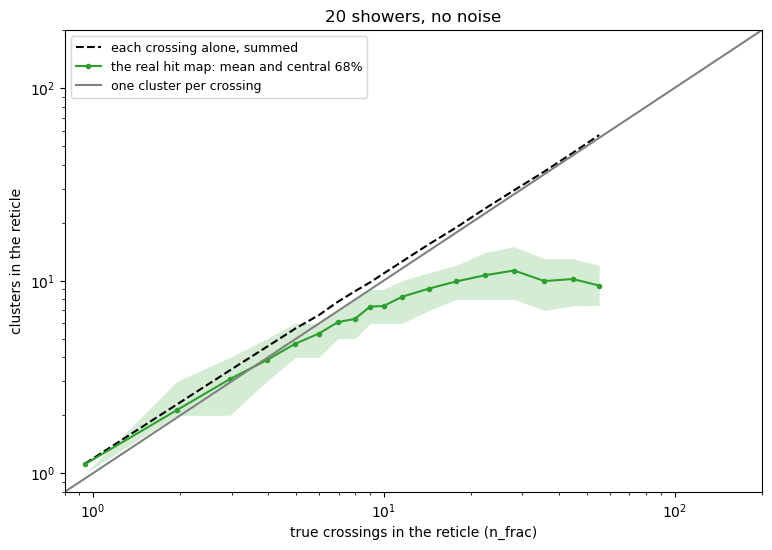

crossings in    reticles   hit pixels per crossing             clusters per crossing
the reticle                alone  together  merged away        alone  together  merged away
          1      33,870    4.73      4.73         0.1%         1.19      1.19         0.7%
          2       5,422    3.84      3.80         0.9%         1.17      1.09         6.5%
          3       1,794    3.40      3.35         1.6%         1.16      1.04         9.9%
        4-5       1,410    3.05      2.98         2.4%         1.14      0.96        15.4%
        6-8         696    2.63      2.52         4.1%         1.11      0.86        22.6%
       9-12         316    2.35      2.21         5.9%         1.09      0.75        30.8%
      13-20         260    2.07      1.90         8.7%         1.07      0.60        44.2%
      21-40         180    1.74      1.46        16.4%         1.05      0.39        63.1%
      41-80          83    1.59      1.19        25.0%         1.03      0.19        81.6%


In [29]:
# every (reticle, crossing) pair with hit pixels gets a hit map of its own: the crossing alone
S = SIZE_X * SIZE_Y
in_ret = (pix_iu - OFFSET_Y - TLc['ru'] * SIZE_Y) * SIZE_X + (pix_iv - OFFSET_X - TLc['rv'] * SIZE_X)
pair, pair_of_row = np.unique(TLc['ret'][hit_row] * n_cross + cross_of_row[hit_row], return_inverse=True)
alone = np.zeros((len(pair), SIZE_Y, SIZE_X), bool)
alone.reshape(-1)[pair_of_row.ravel() * S + in_ret[hit_row]] = True
assert alone.sum() == hit_row.sum() == own20.sum()
_, cl_alone = mc.clusters(alone, PITCH_V, PITCH_U)
n_cl_pair = np.bincount(cl_alone['reticle'], minlength=len(pair))
cl_own20 = np.bincount(pair // n_cross, n_cl_pair, len(TLc['keys']))      # clusters if no two crossings touched
_, cl_tog = mc.clusters(TLc['img'] > THRESHOLD, PITCH_V, PITCH_U)
cl_act20 = np.bincount(cl_tog['reticle'], minlength=len(TLc['keys']))     # clusters of the real hit map
Cown, Cact = profile(nf20, cl_own20), profile(nf20, cl_act20)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(Cown[:, 0], Cown[:, 1], '--', color='k', label='each crossing alone, summed')
ax.fill_between(Cact[:, 0], Cact[:, 2], Cact[:, 3], color='C2', alpha=0.2, lw=0)
ax.plot(Cact[:, 0], Cact[:, 1], 'o-', color='C2', ms=3, label='the real hit map: mean and central 68%')
xx = np.array([0.8, 200])
ax.plot(xx, xx, '-', color='0.5', lw=1.5, label='one cluster per crossing')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.8, 200)
ax.set_ylim(0.8, 200)
ax.set_xlabel('true crossings in the reticle (n_frac)')
ax.set_ylabel('clusters in the reticle')
ax.set_title(f'{int(C["num_events"])} showers, no noise')
ax.legend(fontsize=9, loc='upper left')
plt.show()

k20 = np.rint(nf20)
print("crossings in    reticles   hit pixels per crossing             clusters per crossing")
print("the reticle                alone  together  merged away        alone  together  merged away")
CL_MERGED, PX_MERGED = {}, {}
for lo, hi in mc.TRUTH_BINS[1:]:                 # the bins of notebook 11; fewer than 10 reticles left out
    name = mc._bins_label(lo, hi)
    s = in_bin(k20, lo, hi)
    if s.sum() < 10:
        continue
    n = nf20[s].sum()
    PX_MERGED[name] = 1 - act20[s].sum() / own20[s].sum()
    CL_MERGED[name] = 1 - cl_act20[s].sum() / cl_own20[s].sum()
    print(f"{name:>11s}   {int(s.sum()):9,d}   {own20[s].sum() / n:5.2f}  {act20[s].sum() / n:8.2f}  "
          f"{100 * PX_MERGED[name]:10.1f}%        {cl_own20[s].sum() / n:5.2f}  {cl_act20[s].sum() / n:8.2f}  "
          f"{100 * CL_MERGED[name]:10.1f}%")

Read the table from left to right.

- **Hit pixels, alone.** The pixels a crossing lights on its own already fall steeply with density.
  That is the particle mix: dense reticles sit in the core, where the particles are fast and cross
  the silicon nearly at right angles.
- **Hit pixels, merged away.** Crossings sharing a pixel remove only a small part of the hit pixels
  at moderate density, and a larger but still minor part in the densest reticles.
- **Clusters.** A crossing alone makes slightly more than one cluster (first row of the table): a
  crossing can break into separate pieces, and a crossing on a reticle edge leaves a cluster in
  each reticle it lights while it counts there only by its share. Clusters of different crossings
  start to touch at a few crossings per reticle, and in the densest reticles most of the separate
  clusters are gone.

So in a sparse reticle the hit map shows about one cluster per crossing, a little more where
crossings break up or straddle an edge, and counting clusters comes close to counting crossings.
In a dense reticle the clusters touch: their number falls far below the number of
crossings, while the number of hit pixels still grows with it, at a rate set by the kind of
particles.

**When two crossings merge, what do you see?** The table counts the clusters that merge; here we
look at what a merged cluster is made of. We take whole sensor planes this time (no reticles), the
20 showers of this batch, no noise. On every plane: the hit map (the pixels whose summed charge
passes 1000 e), its 8-connected clusters, and for each cluster its **members**: the crossings
whose own charge alone lights at least one of its pixels. The pixels a crossing lights alone are
its **alone footprint** (section 4 counted them as its own hit pixels). Two words for footprints:

- a **dot**: at most 2 pixels;
- **elongated**: at least 3 pixels, with a long axis at least twice the short one (the principal
  axes of its pixel centres, in um).

Two elongated members whose axes differ by more than 30 degrees would draw an X or a Y.

In [30]:
# every plane of the 20 showers as one hit map, without noise: the summed charge of each pixel
px_key, px_of_row = np.unique(pkey, return_inverse=True)        # pkey (section 5): plane and pixel of every row
px_of_row = px_of_row.ravel()
q_plane = np.bincount(px_of_row, pix_q.astype(np.float64), len(px_key))
hp = np.flatnonzero(q_plane > THRESHOLD)                          # the hit pixels of all planes
hp_plane = px_key[hp] // (2 * KEY_OFF) ** 2
hp_iv = px_key[hp] // (2 * KEY_OFF) % (2 * KEY_OFF) - KEY_OFF
hp_iu = px_key[hp] % (2 * KEY_OFF) - KEY_OFF
PCL = reticles.islands(hp_plane, hp_iv, hp_iu, q_plane[hp], 0, PITCH_V, PITCH_U)   # gap 0: 8-connected clusters
cl_of_hp, n_pcl = PCL['row'], len(PCL['group'])
pcl_size = np.bincount(cl_of_hp, minlength=n_pcl)
cl_of_px = np.full(len(px_key), -1)
cl_of_px[hp] = cl_of_hp

# the members of every cluster: the crossings with a pixel above the threshold on their own in it
ar = np.flatnonzero(hit_row)
cl_ar = cl_of_px[px_of_row[ar]]
assert np.all(cl_ar >= 0), "a pixel that one crossing lights alone is not hit in its plane's map"
mem = np.unique(cl_ar * n_cross + cross_of_row[ar])
mem_cl, mem_x = mem // n_cross, mem % n_cross
n_mem = np.bincount(mem_cl, minlength=n_pcl)
lit_alone = np.flatnonzero(n_hit_cross > 0)
assert np.array_equal(np.unique(mem_x), lit_alone), "the members are not the crossings that light a pixel alone"
print(f"check: every pixel that one crossing lights alone is hit in its plane's map, and the members of the clusters "
      f"are the {len(lit_alone):,} crossings that light a pixel alone ({int(np.sum(np.bincount(mem_x) > 1)):,} of "
      f"them in two clusters or more; {len(mem):,} memberships in all)")

N_PLANES = len(np.unique(row_plane))
N_ONE, N_TWO = int(np.sum(n_mem == 1)), int(np.sum(n_mem == 2))
N_MORE, N_NONE = int(np.sum(n_mem >= 3)), int(np.sum(n_mem == 0))
print(f"\n{N_PLANES} planes, {n_pcl:,} clusters: {N_ONE:,} hold one crossing, {N_TWO:,} two, {N_MORE:,} three or more, "
      f"{N_NONE} none (no pixel of theirs is lit by one crossing alone)")
fp = n_hit_cross[counted]
print(f"alone footprint of the {int(counted.sum()):,} counted crossings: median {np.median(fp):.0f} pixels; "
      f"{np.mean(fp <= 2):.1%} light at most 2 pixels, {np.mean(fp >= 3):.1%} at least 3, {np.mean(fp >= 5):.1%} at least 5")

# the principal axes of every alone footprint: pixel centres in um, around the crossing's charge centroid
xr = cross_of_row[ar]
fx, fy = (pix_iv[ar] + 0.5) * PITCH_V - cv[xr], (pix_iu[ar] + 0.5) * PITCH_U - cu[xr]
nn = np.maximum(n_hit_cross, 1)
mfx, mfy = np.bincount(xr, fx, n_cross) / nn, np.bincount(xr, fy, n_cross) / nn
vxx = np.bincount(xr, fx * fx, n_cross) / nn - mfx ** 2
vyy = np.bincount(xr, fy * fy, n_cross) / nn - mfy ** 2
vxy = np.bincount(xr, fx * fy, n_cross) / nn - mfx * mfy
half, disc = 0.5 * (vxx + vyy), np.sqrt(np.maximum(0.25 * (vxx - vyy) ** 2 + vxy ** 2, 0))
fp_ratio = np.sqrt(np.maximum(half + disc, 0) / np.maximum(half - disc, 1e-9))    # long axis / short axis
fp_angle = np.degrees(0.5 * np.arctan2(2 * vxy, vxx - vyy)) % 180                 # of the long axis, from v
fp_long = (n_hit_cross >= 3) & (fp_ratio >= 2 - 1e-9)     # elongated (a 2 x 2 block is exactly 2: rounding must not decide)

# the clusters of exactly two crossings
two_cl = np.flatnonzero(n_mem == 2)
at = np.searchsorted(mem_cl, two_cl)
xa, xb = mem_x[at], mem_x[at + 1]
sa, sb = n_hit_cross[xa], n_hit_cross[xb]
has_dot = (sa <= 2) | (sb <= 2)
both_long = fp_long[xa] & fp_long[xb]
d_ang = np.abs(fp_angle[xa] - fp_angle[xb])
d_ang = np.minimum(d_ang, 180 - d_ang)
x_or_y = both_long & (d_ang > 30)
n_alone_px = np.bincount(px_of_row[ar], minlength=len(px_key))      # crossings lighting each pixel alone
most_alone = np.zeros(n_pcl, np.int64)
np.maximum.at(most_alone, cl_of_hp, n_alone_px[hp])
shared = most_alone[two_cl] >= 2                                   # a pixel lit alone by both members
# do the footprints touch: is a pixel of one footprint, or one of its 8 neighbours, a pixel of the other?
pair_of_cl = np.full(n_pcl, -1)
pair_of_cl[two_cl] = np.arange(N_TWO)
j_ar = pair_of_cl[cl_ar]
side_a = (j_ar >= 0) & (cross_of_row[ar] == xa[np.maximum(j_ar, 0)])
side_b = (j_ar >= 0) & (cross_of_row[ar] == xb[np.maximum(j_ar, 0)])
touch = np.zeros(N_TWO, bool)
for dv in (-1, 0, 1):
    for du in (-1, 0, 1):
        near = np.isin(pkey[ar][side_a] + dv * 2 * KEY_OFF + du, pkey[ar][side_b])
        touch[j_ar[side_a][near]] = True
print(f"\n{N_TWO:,} clusters of exactly two crossings:")
print(f"  at least one member is a dot: {has_dot.mean():.1%}; both light at least 3 pixels: {np.mean((sa >= 3) & (sb >= 3)):.1%}")
print(f"  both elongated: {both_long.mean():.1%} ({int(both_long.sum()):,}); of those, axes more than 30 degrees apart: "
      f"{np.mean(d_ang[both_long] > 30):.1%}; so a visible X or Y in {x_or_y.mean():.1%} of the pairs ({int(x_or_y.sum())})")
print(f"  the two footprints share a pixel: {shared.mean():.1%}; touch without sharing one: {np.mean(touch & ~shared):.1%}; "
      f"neither, joined only through pixels that no crossing lights alone: {np.mean(~touch):.1%} ({int(np.sum(~touch))})")
assert not np.any(shared & ~touch), "two footprints share a pixel but do not touch"
s1, s2 = pcl_size[n_mem == 1], pcl_size[two_cl]
print(f"cluster size in pixels: one crossing median {np.median(s1):.0f} (90th percentile {np.percentile(s1, 90):.0f}); "
      f"two crossings median {np.median(s2):.0f} (10th percentile {np.percentile(s2, 10):.0f}, 90th "
      f"{np.percentile(s2, 90):.0f}); {np.mean(s2 <= np.median(s1)):.1%} of the two-crossing clusters are no bigger "
      f"than the median one-crossing cluster")
p_mem = C['group_root_p_MeV'][cross_group[np.r_[xa, xb]]]
print(f"momentum of the members: median {np.median(p_mem):.1f} MeV/c")

# where the pairs sit: distance of the cluster's pixel centroid from the axis, axis module only
pcl_mod = PCL['group'] // N_LAYERS % N_FACES
pcl_r = np.hypot(np.bincount(cl_of_hp, (hp_iv + 0.5) * PITCH_V, n_pcl),
                 np.bincount(cl_of_hp, (hp_iu + 0.5) * PITCH_U, n_pcl)) / pcl_size * 1e-3
on_axis2 = pcl_mod[two_cl] == AXIS_MODULE
print("\ndistance from axis   pairs   with a dot   both dots   X or Y   median momentum [MeV/c]")
PAIR_R = []
for lo, hi in ((0, 0.5), (0.5, 2), (2, np.inf)):
    s = on_axis2 & (pcl_r[two_cl] >= lo) & (pcl_r[two_cl] < hi)
    PAIR_R.append((lo, hi, has_dot[s].mean(), np.mean((sa[s] <= 2) & (sb[s] <= 2)), x_or_y[s].mean()))
    print(f"{lo:4.1f} to {hi:4.1f} mm   {int(s.sum()):5,d}   {100 * PAIR_R[-1][2]:9.1f}%   {100 * PAIR_R[-1][3]:8.1f}%   "
          f"{100 * PAIR_R[-1][4]:5.1f}%   {np.median(C['group_root_p_MeV'][cross_group[np.r_[xa[s], xb[s]]]]):23.1f}")

th_v, th_u = (np.degrees(np.arctan(2 * p / THICK)) for p in (PITCH_V, PITCH_U))
print(f"\ngeometry: a track at an angle theta to the normal moves {THICK:g} um x tan(theta) sideways, and spans 3 "
      f"pixels in a row wherever it enters once that reaches two pitches: theta above {th_v:.0f} degrees along v "
      f"({PITCH_V:g} um pixels), above {th_u:.0f} degrees along u ({PITCH_U:g} um pixels)")

assert (N_PLANES, n_pcl, N_ONE, N_TWO, N_MORE, int(both_long.sum()), int(x_or_y.sum())) == \
       (604, 67547, 62021, 3704, 1820, 824, 547), "the counts differ from those quoted in the text below"
print("check: the counts are those quoted in the text below")

check: every pixel that one crossing lights alone is hit in its plane's map, and the members of the clusters are the 78,473 crossings that light a pixel alone (2,532 of them in two clusters or more; 81,697 memberships in all)

604 planes, 67,547 clusters: 62,021 hold one crossing, 3,704 two, 1,820 three or more, 2 none (no pixel of theirs is lit by one crossing alone)
alone footprint of the 78,578 counted crossings: median 3 pixels; 49.5% light at most 2 pixels, 50.5% at least 3, 24.6% at least 5



3,704 clusters of exactly two crossings:
  at least one member is a dot: 75.9%; both light at least 3 pixels: 24.1%
  both elongated: 22.2% (824); of those, axes more than 30 degrees apart: 66.4%; so a visible X or Y in 14.8% of the pairs (547)
  the two footprints share a pixel: 33.2%; touch without sharing one: 66.7%; neither, joined only through pixels that no crossing lights alone: 0.1% (4)
cluster size in pixels: one crossing median 3 (90th percentile 9); two crossings median 5 (10th percentile 2, 90th 14); 31.9% of the two-crossing clusters are no bigger than the median one-crossing cluster
momentum of the members: median 13.2 MeV/c

distance from axis   pairs   with a dot   both dots   X or Y   median momentum [MeV/c]
 0.0 to  0.5 mm     961        95.0%       61.8%     2.4%                      33.9
 0.5 to  2.0 mm   1,943        74.5%       30.8%    15.1%                      12.7
 2.0 to  inf mm     800        56.4%       16.9%    28.7%                       5.9

geometry: a

Most clusters hold one crossing; a few thousand hold two (the printed counts). A crossing alone
lights at most 2 pixels about half the time, so a merged pair usually contains a dot: in three
pairs out of four at least one member is a dot. Both members are elongated in about a fifth of the
pairs, and in two thirds of those their axes differ by more than 30 degrees: a visible X or Y in
about one pair in seven. The two footprints share a pixel in a third of the pairs, and in nearly
all the others they touch.

The cluster size does not tell a merged pair from a single crossing: a two-crossing cluster has a
median of 5 pixels against 3 for one crossing, and a third of the two-crossing clusters are no
bigger than the median single one. The geometry line gives the scale of a dot: a track spans 3
pixels in a row wherever it enters only beyond about 45 degrees from the normal along v, or 27
degrees along u.

The table by distance shows where the pairs with a dot sit. Within 0.5 mm of the axis nearly every
merged pair holds a dot, most of them two dots, and an X or a Y is rare; beyond 2 mm, where the
particles carry less momentum (the printed medians), a dot is in a little over half of the pairs
and an X or a Y in more than a quarter. Below, eight merged pairs from the axis module: four that
draw an X or a Y (top) and four that are a dot against a line (bottom).

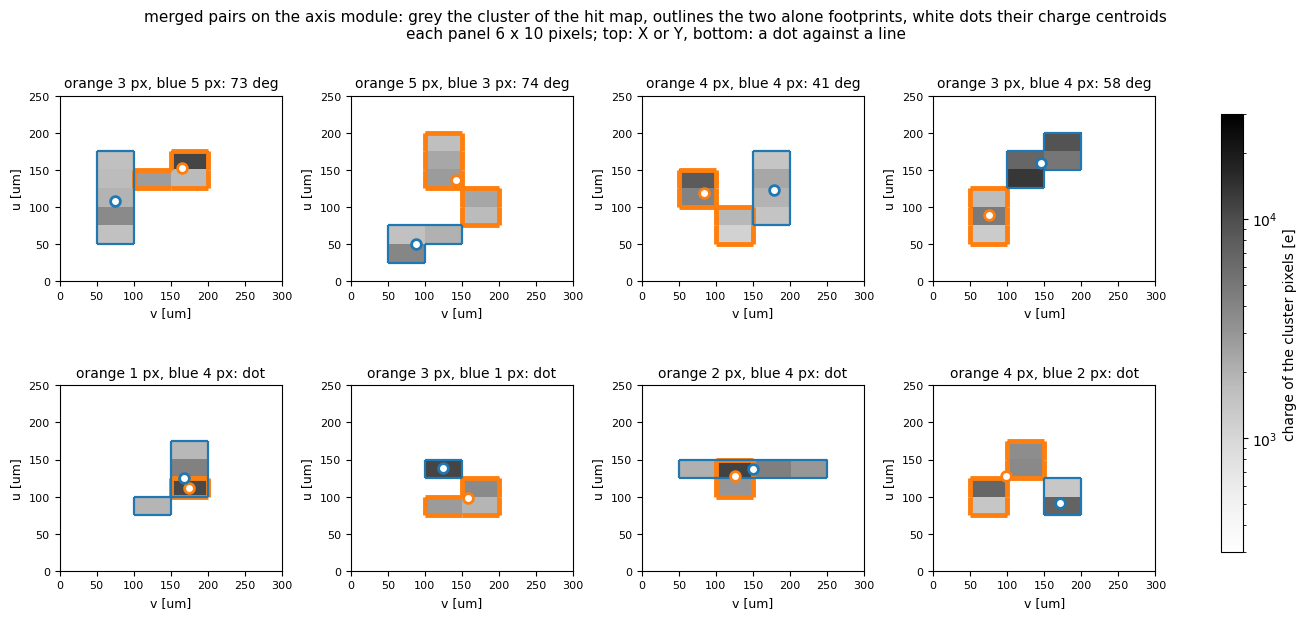

pairs on the axis module whose two footprints lie inside the cluster and fit the window: 210 X or Y, 1095 a dot against a line (four of each drawn at random)


In [31]:
# eight merged pairs: four whose members are both elongated with axes more than 30 degrees apart, four dots against a line
NV_W, NU_W = 6, 10                                                  # the window of each panel, in pixels
o = np.argsort(cl_of_hp, kind='stable')
st = np.r_[0, np.cumsum(pcl_size)[:-1]]
v_lo, v_hi = np.minimum.reduceat(hp_iv[o], st), np.maximum.reduceat(hp_iv[o], st)
u_lo, u_hi = np.minimum.reduceat(hp_iu[o], st), np.maximum.reduceat(hp_iu[o], st)
fits = (v_hi - v_lo + 3 <= NV_W) & (u_hi - u_lo + 3 <= NU_W)          # the cluster and a margin fit the window
in_cl = np.bincount(np.searchsorted(mem, cl_ar * n_cross + cross_of_row[ar]), minlength=len(mem))
whole = (in_cl[at] == sa) & (in_cl[at + 1] == sb)                    # both footprints lie inside the cluster
ok = on_axis2 & fits[two_cl] & whole
dot_line = ((sa <= 2) & fp_long[xb]) | ((sb <= 2) & fp_long[xa])
rng = np.random.default_rng(SEED)
SHOW = [np.sort(rng.choice(np.flatnonzero(ok & x_or_y), 4, replace=False)),
        np.sort(rng.choice(np.flatnonzero(ok & dot_line), 4, replace=False))]


def outline(ax, jx, jy, color, lw):
    # the outer edges of a set of pixels (window columns jx, rows jy)
    on = set(zip(jx.tolist(), jy.tolist()))
    seg = []
    for x, y in on:
        x0, x1, y0, y1 = x * PITCH_V, (x + 1) * PITCH_V, y * PITCH_U, (y + 1) * PITCH_U
        seg += [[(x0, y0), (x0, y1)]] if (x - 1, y) not in on else []
        seg += [[(x1, y0), (x1, y1)]] if (x + 1, y) not in on else []
        seg += [[(x0, y0), (x1, y0)]] if (x, y - 1) not in on else []
        seg += [[(x0, y1), (x1, y1)]] if (x, y + 1) not in on else []
    ax.add_collection(LineCollection(seg, colors=color, linewidths=lw))


FP_COL = ('C1', 'C0')                                               # orange and blue
fig, axs = plt.subplots(2, 4, figsize=(13, 6.2), constrained_layout=True)
ext = (0, NV_W * PITCH_V, 0, NU_W * PITCH_U)
for r_, (row_axs, js) in enumerate(zip(axs, SHOW)):
    for ax, j in zip(row_axs, js):
        c = two_cl[j]
        iv0 = v_lo[c] - (NV_W - (v_hi[c] - v_lo[c] + 1)) // 2              # the cluster centred, a margin on each side
        iu0 = u_lo[c] - (NU_W - (u_hi[c] - u_lo[c] + 1)) // 2
        a, b = np.searchsorted(plane_sorted, PCL['group'][c], 'left'), np.searchsorted(plane_sorted, PCL['group'][c], 'right')
        rows = by_plane[a:b]
        q = pixel_image(pix_iv[rows], pix_iu[rows], pix_q[rows], iv0, iu0, NV_W, NU_W)
        mask = np.zeros((NU_W, NV_W), bool)
        mask[hp_iu[cl_of_hp == c] - iu0, hp_iv[cl_of_hp == c] - iv0] = True
        im = ax.imshow(np.where(mask, q, np.nan), origin='lower', interpolation='nearest', extent=ext,
                       norm=LogNorm(vmin=300, vmax=3e4), cmap='Greys')
        for x, col, lw in zip((xa[j], xb[j]), FP_COL, (3.5, 1.6)):
            rx = order_c[starts_c[x]:starts_c[x + 1]]
            rx = rx[hit_row[rx]]
            outline(ax, pix_iv[rx] - iv0, pix_iu[rx] - iu0, col, lw)
        for x, col in zip((xa[j], xb[j]), FP_COL):
            ax.plot(cv[x] - iv0 * PITCH_V, cu[x] - iu0 * PITCH_U, 'o', mfc='white', mec=col, mew=2, ms=7)
        how = f'{d_ang[j]:.0f} deg' if r_ == 0 else 'dot'
        ax.set_title(f'orange {sa[j]} px, blue {sb[j]} px: {how}', fontsize=10)
        ax.set_xlim(ext[0], ext[1])
        ax.set_ylim(ext[2], ext[3])
        ax.set_xlabel('v [um]', fontsize=9)
        ax.set_ylabel('u [um]', fontsize=9)
        ax.tick_params(labelsize=8)
fig.colorbar(im, ax=axs, label='charge of the cluster pixels [e]', fraction=0.02)
fig.suptitle(f'merged pairs on the axis module: grey the cluster of the hit map, outlines the two alone footprints, '
             f'white dots their charge centroids\neach panel {NV_W} x {NU_W} pixels; top: X or Y, bottom: a dot against a line',
             fontsize=11)
plt.show()
print(f"pairs on the axis module whose two footprints lie inside the cluster and fit the window: "
      f"{int(np.sum(ok & x_or_y))} X or Y, {int(np.sum(ok & dot_line))} a dot against a line (four of each drawn at random)")

Even in the top row the X or Y is hard to read: an elongated footprint is three to a few pixels
long, and the merged cluster is a small blob with a few arms. In the bottom row the dot sits on or
next to the line and adds a pixel or two to it.

So the direction of the members can be read in a minority of merged pairs, and almost never in the
core. There the particles are fast and cross the silicon nearly at right angles (section 4; the
write-up, section 6.3, says the same of the dense reticles), so a merged cluster in the core is
mostly dots on dots.

Neither the number of hit pixels nor the number of clusters is one fixed multiple of the number
of crossings. **Notebook 11 asks the next question: given only the hit map of a reticle, how well
can the number of crossings in it be estimated, and how does that depend on density?**

## 8. Summary

The six points below are printed from the numbers measured in this notebook.

In [32]:
print(f"1. Charge is deposited energy / {EV_PER_PAIR} eV: on the display plane the ratio is "
      f"{q_grp_sum / pairs:.5f}, and the pixel charges add up to the particles' charges.")
print(f"2. One crossing (a connected patch of one particle's pixels) carries a most probable "
      f"{mpv / 1e3:.1f} ke (median {med_q / 1e3:.1f} ke; the formula for a fast particle gives "
      f"{mip_mpv_e / 1e3:.1f} ke) and lights "
      f"{mean_hits:.1f} pixels above {THRESHOLD:g} e on average: {100 * SHARES['spot']:.0f}% spots, "
      f"{100 * SHARES['thin line']:.0f}% thin lines, {100 * SHARES['other']:.0f}% other; median extent "
      f"{np.median(extent[seen]):.0f} um.")
print(f"3. With {NOISE:g} e noise and a {THRESHOLD:g} e threshold, {100 * LOST_SHARE:.2f}% of the counted crossings "
      f"light no pixel; noise makes {noise_hits} hits in the empty pixels of the display plane and "
      f"{NOISE_HITS_K1} in those of the {len(nf1):,} single-shower reticles.")
print(f"4. The truth is the crossing: {100 * np.mean(n_cross_of_group[grp_counted] > 1):.0f}% of the particles cross "
      f"a plane more than once, and a crossing touches {RET_PER_CROSS:.2f} reticles on average; n_frac and n_own "
      f"sum to the crossings of every plane and agree reticle by reticle with mip_counting.truths.")
print(f"5. Density: in single showers {100 * TABLE['K1'][0][1]:.0f}% of the reticles holding charge hold one "
      f"crossing, and {100 * TABLE['K1'][1][4]:.0f}% of the crossings sit in reticles above 20 "
      f"({100 * TABLE['K8'][1][4]:.0f}% for stacks of eight). Hit pixels per crossing fall from "
      f"{HPC['K1']['1']:.1f} at one crossing to {HPC['K1']['13-20']:.1f} at 13 to 20, mostly because dense "
      f"reticles hold fast particles (merging removes {100 * PX_MERGED['13-20']:.0f}% of the pixels there); within "
      f"{MERGE[0][1]:g} mm of the axis, stacking eight showers lowers it from {MERGE[0][2]:.2f} to "
      f"{MERGE[0][3]:.2f} by merging.")
print(f"6. Clusters merge long before pixels: at 13 to 20 crossings per reticle, touching removes "
      f"{100 * CL_MERGED['13-20']:.0f}% of the separate clusters but only {100 * PX_MERGED['13-20']:.0f}% "
      f"of the hit pixels; at 41 to 80 crossings, {100 * CL_MERGED['41-80']:.0f}% and "
      f"{100 * PX_MERGED['41-80']:.0f}%.")
print(f"7. On the {N_PLANES} whole planes of the batch, {N_TWO:,} of the {n_pcl:,} clusters hold exactly two crossings: "
      f"at least one member is a dot in {100 * has_dot.mean():.0f}% of them, a visible X or Y in {100 * x_or_y.mean():.0f}%; "
      f"within 0.5 mm of the axis {100 * PAIR_R[0][2]:.0f}% hold a dot and {100 * PAIR_R[0][4]:.0f}% an X or Y.")
peak = None
try:
    import resource
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e6 if sys.platform == 'darwin' else 1e3)
except ImportError:
    pass
print(f"\nrun time {time.time() - T_START:.0f} s" + (f", peak memory {peak:,.0f} MB" if peak else ""))

1. Charge is deposited energy / 3.68 eV: on the display plane the ratio is 1.00000, and the pixel charges add up to the particles' charges.
2. One crossing (a connected patch of one particle's pixels) carries a most probable 7.7 ke (median 10.2 ke; the formula for a fast particle gives 7.1 ke) and lights 4.1 pixels above 1000 e on average: 66% spots, 28% thin lines, 6% other; median extent 103 um.
3. With 100 e noise and a 1000 e threshold, 0.12% of the counted crossings light no pixel; noise makes 0 hits in the empty pixels of the display plane and 0 in those of the 600,628 single-shower reticles.
4. The truth is the crossing: 17% of the particles cross a plane more than once, and a crossing touches 1.31 reticles on average; n_frac and n_own sum to the crossings of every plane and agree reticle by reticle with mip_counting.truths.
5. Density: in single showers 57% of the reticles holding charge hold one crossing, and 13% of the crossings sit in reticles above 20 (35% for stacks of eig